# **Facial Emotion Recognition**

**Project Type** : Deep Learning / Computer Vision

**Contribution** : Individual

# Project Summary
This project focuses on building a deep learning pipeline for Facial Emotion Recognition using the FER dataset. We train and evaluate EfficientNet-B0 and MobileNetV3-Large models with data augmentation, class-weighted loss, learning rate schedulers, and Grad-CAM. The goal is to achieve an accuracy of 80–85% and deploy it through a Gradio web interface.

## **1. Environment Setup and Data Understanding**

We load the training and validation datasets using ImageFolder, display the emotion classes, and get an overview of the dataset structure and class distribution. We also configure the device to use GPU if available.

### **1.1. Imports and Setup**

In [2]:
# =============================
# 1.1 IMPORTS & SETUP
# =============================

import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from PIL import Image

# PyTorch core
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset

# Torchvision
from torchvision import transforms, datasets, models
from torchvision.datasets import ImageFolder

# Optional (keep but not needed immediately)
import timm
import albumentations as A
from albumentations.pytorch import ToTensorV2

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Device config
SEED = 42
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Dataset paths
base_dir = '/content/drive/MyDrive/FER/facial recognition dataset/images'
train_dir = os.path.join(base_dir, 'train')
val_dir = os.path.join(base_dir, 'validation')

# Preview dataset
train_dataset_preview = ImageFolder(train_dir)
class_names = train_dataset_preview.classes

print("Classes:", class_names)
print("Number of classes:", len(class_names))

Mounted at /content/drive
Using device: cuda
Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Number of classes: 7


### **1.2. Sample Images Per Class**

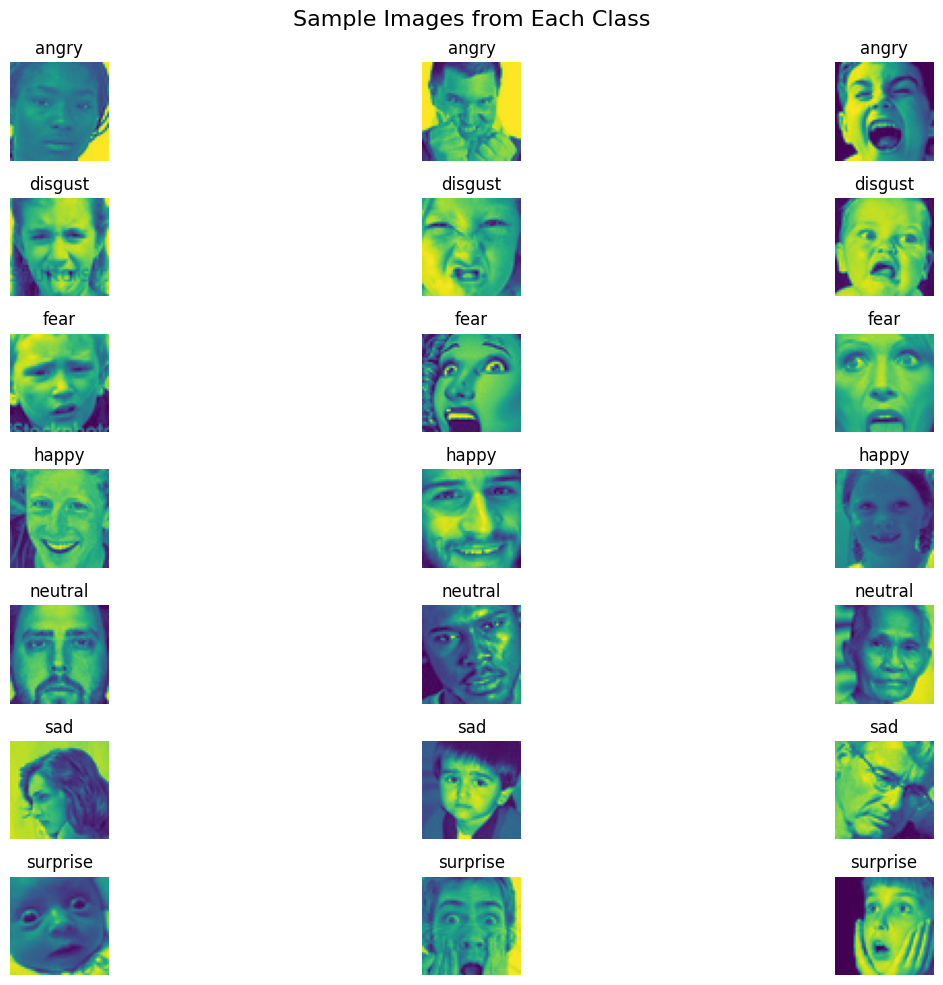

In [3]:
# ================================
# 1.2. Show Sample Images Per Class
# ================================

import random
import matplotlib.pyplot as plt
from PIL import Image
import os

def show_sample_images(directory, class_names, samples_per_class=3):
    plt.figure(figsize=(15, 10))

    plot_index = 1

    for label in class_names:
        class_path = os.path.join(directory, label)
        images = os.listdir(class_path)

        # Safety check
        if len(images) == 0:
            print(f"⚠️ No images found in class: {label}")
            continue

        selected_images = random.sample(images, min(samples_per_class, len(images)))

        for img_name in selected_images:
            img_path = os.path.join(class_path, img_name)
            image = Image.open(img_path)

            plt.subplot(len(class_names), samples_per_class, plot_index)
            plt.imshow(image)
            plt.title(label)
            plt.axis('off')

            plot_index += 1

    plt.suptitle('Sample Images from Each Class', fontsize=16)
    plt.tight_layout()
    plt.show()

# Call function
show_sample_images(train_dir, class_names, samples_per_class=3)


### **a. Why did you pick this visual inspection technique ?**

Sample image visualization was chosen to qualitatively understand the dataset. Unlike numerical datasets, image datasets require visual inspection to identify patterns such as facial expressions, lighting conditions, pose variations, and noise. This step helps validate whether the dataset is suitable for training a facial emotion recognition model.

### **b. What insights were found ?**

The sample images reveal significant diversity in facial expressions across different emotion classes. While emotions like happiness and surprise show strong visual cues, others such as neutral and sadness are more subtle and may overlap. Additionally, variations in lighting, facial orientation, and presence of noise (e.g., watermarks) were observed. These factors highlight the need for preprocessing and augmentation techniques to improve model generalization.

### **c. Will the insights help create positive business impact?**

Yes, these insights directly contribute to improving model performance, which is critical for real-world applications such as customer sentiment analysis, mental health monitoring, and user experience enhancement. Understanding dataset variability allows for better preprocessing and model design, leading to more accurate emotion detection and improved decision-making systems.

### **d. Any insights that may lead to negative growth?**

Yes, certain insights may negatively impact model performance. Subtle differences between classes such as neutral and sad may lead to misclassification. Additionally, the presence of noise and watermarks can cause the model to learn irrelevant features, reducing its generalization ability. Variations in lighting and pose can further introduce inconsistencies, potentially affecting prediction accuracy.

## **2. Data Exploration & Visualization**

Perform class distribution plots.

### **2.1. Class Distribution**

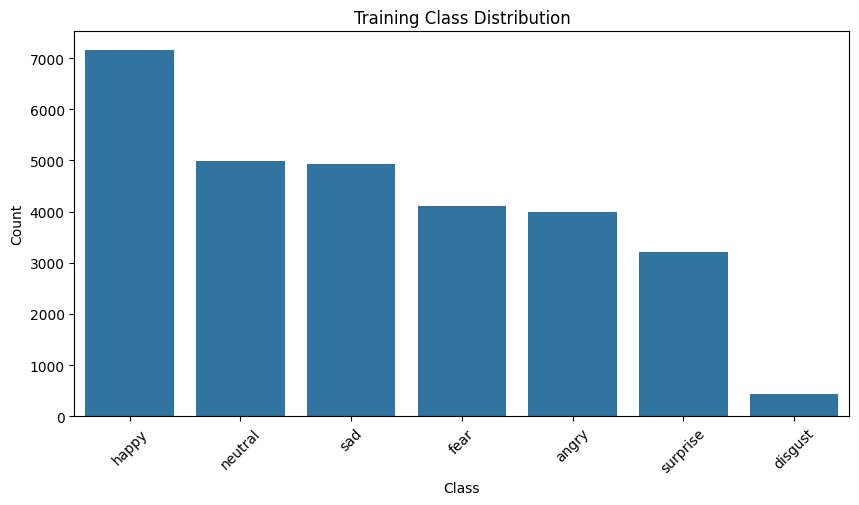

Training Distribution:


,Class,Count
3,happy,7164
0,neutral,4982
2,sad,4938
4,fear,4103
5,angry,4003
1,surprise,3205
6,disgust,436


             Count
count     7.000000
mean   4118.714286
std    2045.366773
min     436.000000
25%    3604.000000
50%    4103.000000
75%    4960.000000
max    7164.000000


In [4]:
# ================================
# 2.1.: Class Distribution
# ================================

import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def get_class_distribution(directory):
    data = []
    for label in os.listdir(directory):
        class_path = os.path.join(directory, label)

        if os.path.isdir(class_path):
            count = len(os.listdir(class_path))
            data.append([label, count])

    df = pd.DataFrame(data, columns=['Class', 'Count'])
    return df.sort_values(by='Count', ascending=False)

# Get distributions
train_df = get_class_distribution(train_dir)
val_df = get_class_distribution(val_dir)

# Plot
plt.figure(figsize=(10,5))
sns.barplot(data=train_df, x='Class', y='Count')
plt.title("Training Class Distribution")
plt.xticks(rotation=45)
plt.show()

# Display table
print("Training Distribution:")
display(train_df)
print(train_df.describe())

### **a. Why did you pick this chart?**

A bar plot was selected to visualize the distribution of images across different emotion classes because it provides a clear comparison of categorical frequencies. This is essential in classification problems to identify class imbalance, which directly affects model training and performance.

### **b. Insights from the data**

The class distribution reveals a significant imbalance in the dataset. The “happy” class has the highest number of samples (7164), while “disgust” has only 436 samples, indicating a severe imbalance of approximately 16:1. Other classes such as neutral and sad have moderate representation, while surprise and fear are relatively lower. The high standard deviation further confirms uneven distribution across classes.

### **c. Will the insights help create positive business impact?**

These insights are critical for building a reliable emotion recognition system. Without addressing class imbalance, the model may favor dominant emotions such as happiness, leading to biased predictions. In real-world applications like customer sentiment analysis or mental health monitoring, this could result in inaccurate interpretations of user emotions. Proper handling of imbalance ensures fair and accurate predictions across all emotional states, improving system reliability and trustworthiness.

### **d. Any insights that may lead to negative growth?**

The severe underrepresentation of the “disgust” class can significantly degrade model performance for this emotion, leading to poor recall and frequent misclassification. Additionally, the dominance of the “happy” class may bias the model toward predicting happiness even when incorrect. This imbalance can result in misleading outputs, especially in sensitive applications such as behavioral analysis or human-computer interaction systems.

This imbalance necessitates the use of techniques such as class weighting, data augmentation, or resampling to improve model fairness and performance.

### **2.2. Representative vs Low-Contrast Emotion Samples**

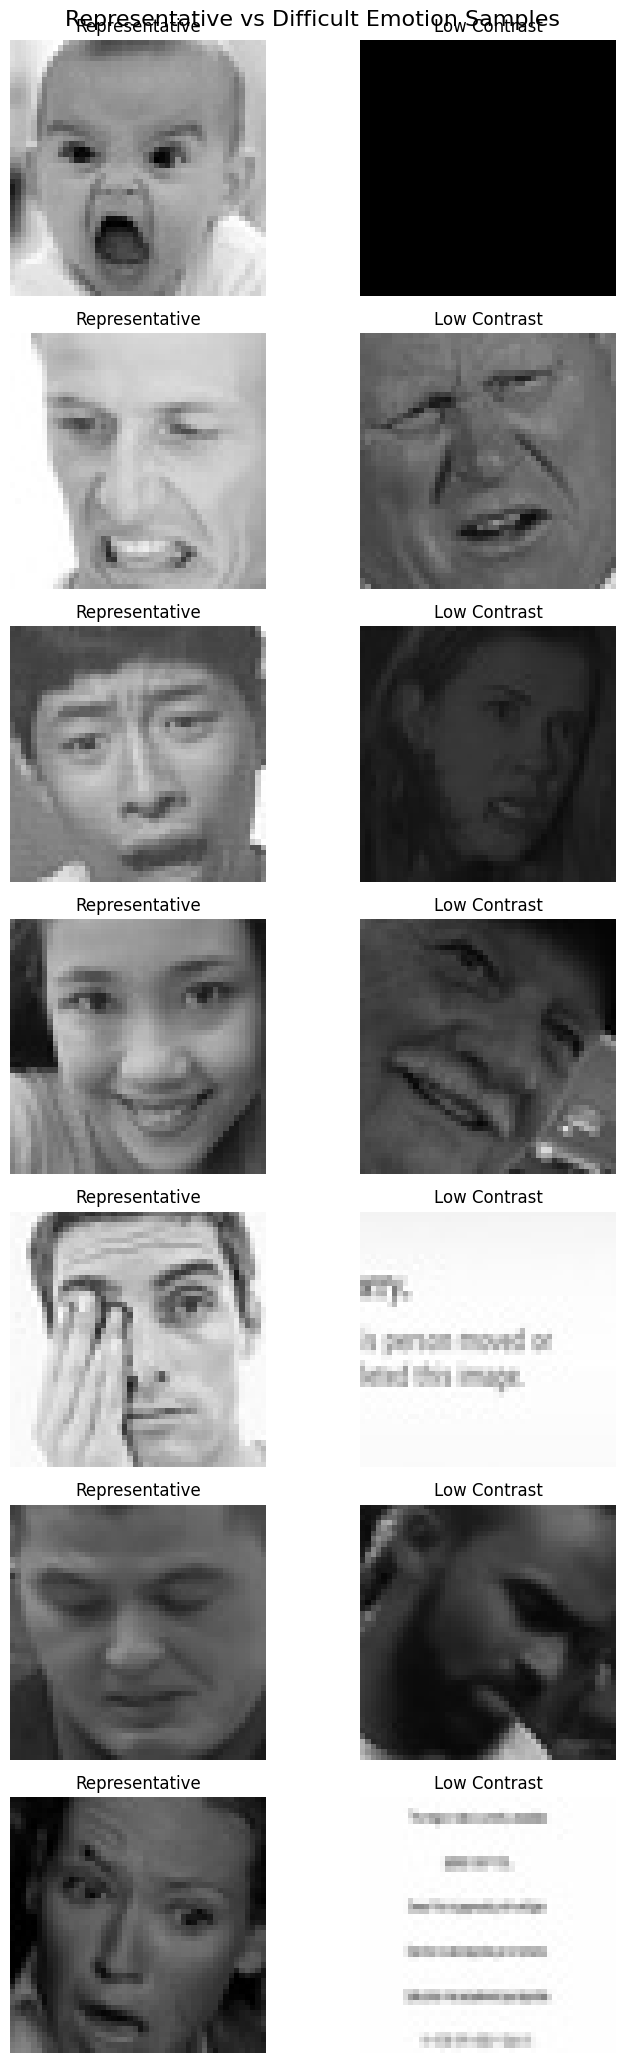

In [5]:
import random
import cv2
import numpy as np
import os
import matplotlib.pyplot as plt
from PIL import Image

def image_contrast_score(image_path):
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    return np.std(img)

def show_difficult_cases(data_dir, class_names, sample_size=100):

    fig, axes = plt.subplots(
        len(class_names),
        2,
        figsize=(8, 3*len(class_names))
    )

    fig.suptitle(
        "Representative vs Difficult Emotion Samples",
        fontsize=16
    )

    for row, emotion in enumerate(class_names):

        class_path = os.path.join(data_dir, emotion)

        image_files = [
            os.path.join(class_path, img)
            for img in os.listdir(class_path)
        ]

        # Representative image
        representative = random.choice(image_files)

        # Only evaluate subset
        subset = random.sample(
            image_files,
            min(sample_size, len(image_files))
        )

        difficult = min(
            subset,
            key=image_contrast_score
        )

        for col, img_path in enumerate([representative, difficult]):

            img = Image.open(img_path).convert("RGB")

            axes[row, col].imshow(img)
            axes[row, col].axis("off")

            if col == 0:
                axes[row, col].set_title("Representative")
            else:
                axes[row, col].set_title("Low Contrast")

        axes[row, 0].set_ylabel(
            emotion,
            rotation=90,
            fontsize=11
        )

    plt.tight_layout()
    plt.show()

show_difficult_cases(train_dir, class_names)

### **a. Why did you pick this visualization?**

This visualization was selected to compare representative emotion samples with visually challenging samples exhibiting reduced contrast and image quality. The objective is to understand how variations in image quality may affect emotion recognition performance and model robustness.

### **b. What insights were found?**

The visualization reveals substantial variation in image quality across emotion classes. While representative images contain clear facial features and strong emotional cues, low-contrast samples exhibit reduced visibility of critical facial regions. Such variations may increase classification difficulty, particularly for emotions that are already visually similar. The presence of these challenging samples indicates the importance of robust preprocessing and augmentation strategies.

### **c. Will the gained insights help create a positive business impact?**

These insights help improve model robustness by highlighting the need to train on diverse image conditions. A model capable of accurately recognizing emotions under varying lighting and contrast conditions can perform more reliably in real-world environments such as customer feedback systems, online learning platforms, healthcare monitoring systems, and human-computer interaction applications. Improved robustness leads to better user experience and increased trust in the system.

### **d. Are there any insights that lead to negative growth?**

Low-quality images may negatively impact model performance because important facial features become less visible. This can increase misclassification rates, especially for emotions that depend on subtle facial expressions. If the model is not trained to handle such variations, prediction reliability may decrease when deployed in real-world environments with inconsistent lighting and image quality.

### **e. Why did you perform this EDA?**

This analysis was performed to evaluate dataset robustness. Since real-world facial images are captured under different lighting and camera conditions, identifying low-contrast samples helps justify the use of preprocessing techniques, data augmentation, and deep learning architectures capable of learning invariant facial representations.

### **2.3. Image Height & Width Distribution**

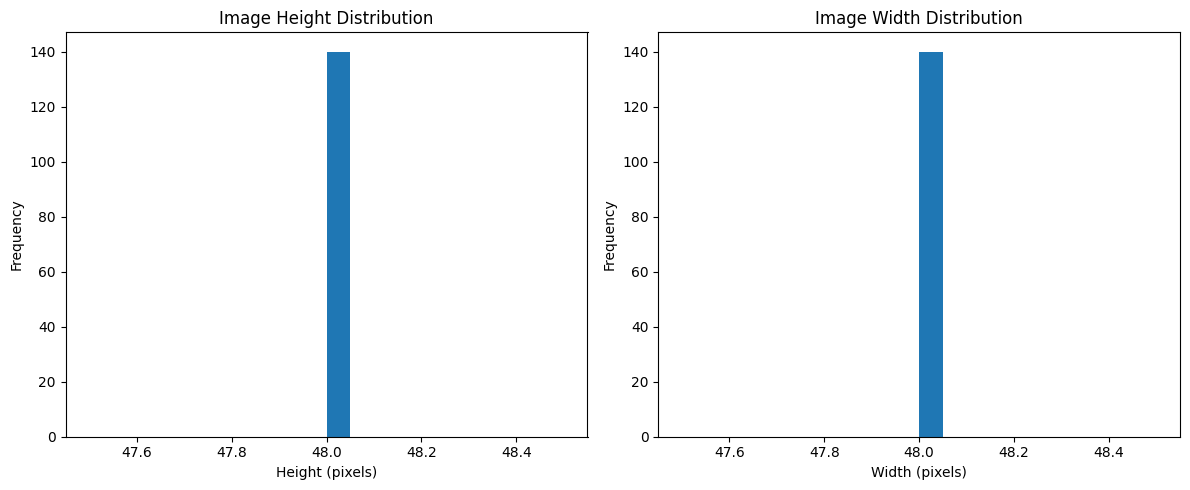

Unique Heights: [48]
Unique Widths: [48]
Height Statistics
count    140.0
mean      48.0
std        0.0
min       48.0
25%       48.0
50%       48.0
75%       48.0
max       48.0
dtype: float64

Width Statistics
count    140.0
mean      48.0
std        0.0
min       48.0
25%       48.0
50%       48.0
75%       48.0
max       48.0
dtype: float64


In [6]:
# ================================
# 2.3. : Image Height & Width Distribution
# ================================

import os
import cv2
import random
import matplotlib.pyplot as plt

image_heights = []
image_widths = []

sample_size = 20

for label in class_names:

    label_folder = os.path.join(train_dir, label)

    image_files = os.listdir(label_folder)

    selected_files = random.sample(
        image_files,
        min(sample_size, len(image_files))
    )

    for img_file in selected_files:

        img_path = os.path.join(label_folder, img_file)

        img = cv2.imread(img_path)

        if img is not None:

            h, w = img.shape[:2]

            image_heights.append(h)
            image_widths.append(w)

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.hist(image_heights, bins=20)
plt.title("Image Height Distribution")
plt.xlabel("Height (pixels)")
plt.ylabel("Frequency")

plt.subplot(1,2,2)
plt.hist(image_widths, bins=20)
plt.title("Image Width Distribution")
plt.xlabel("Width (pixels)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

print("Unique Heights:", sorted(set(image_heights)))
print("Unique Widths:", sorted(set(image_widths)))

print("Height Statistics")
print(pd.Series(image_heights).describe())

print("\nWidth Statistics")
print(pd.Series(image_widths).describe())

### **a. Why did you pick this chart?**

Histograms were used to analyze the distribution of image heights and widths across the dataset. Understanding image dimensions is an important preprocessing step because deep learning models require fixed-size inputs. This analysis helps determine whether image resizing or dimension standardization is necessary before training.

### **b. What insights were found?**

The analysis reveals that all images in the dataset have a uniform resolution of 48 × 48 pixels. The height and width distributions contain only a single value, and the standard deviation of both dimensions is zero, confirming complete consistency across all samples. This indicates that the dataset has already been standardized and does not contain images with varying spatial dimensions.

### **c. Will the gained insights help create a positive business impact?**

Uniform image dimensions simplify the preprocessing pipeline and reduce computational overhead during model training. Since all images already share the same resolution, additional resizing operations are unnecessary, leading to faster data loading and more consistent model inputs. This improves training efficiency and reduces the risk of preprocessing-related errors during deployment.

### **d. Are there any insights that lead to negative growth?**

Although uniform image dimensions provide consistency, the relatively low resolution of 48 × 48 pixels may limit the amount of facial detail available to the model. Fine-grained emotional cues such as subtle eyebrow movements, wrinkles, or mouth variations may be less distinguishable at this resolution. Consequently, differentiating between visually similar emotions may become more challenging.

### **2.4. Image Channel Distribution**

Image Modes: Counter({'L': 28831})


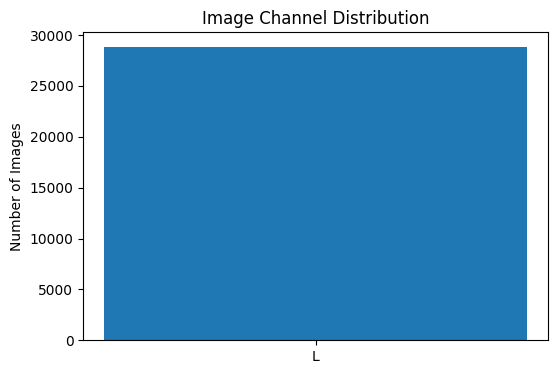

In [7]:
from collections import Counter
from PIL import Image
import os
import pandas as pd
import matplotlib.pyplot as plt

modes = Counter()

for label in class_names:

    label_folder = os.path.join(train_dir, label)

    for img_file in os.listdir(label_folder):

        img_path = os.path.join(label_folder, img_file)

        try:
            with Image.open(img_path) as img:
                modes[img.mode] += 1
        except:
            pass

print("Image Modes:", modes)

mode_df = pd.DataFrame(
    modes.items(),
    columns=["Image Mode", "Count"]
)

plt.figure(figsize=(6,4))
plt.bar(mode_df["Image Mode"], mode_df["Count"])
plt.title("Image Channel Distribution")
plt.ylabel("Number of Images")
plt.show()

### **a. Why did you pick this chart?**

A bar chart was used to analyze the distribution of image channel types within the dataset. Understanding whether images are grayscale or RGB is important because it directly affects preprocessing decisions, model architecture compatibility, memory requirements, and feature extraction strategies.

### **b. What insights were found?**

The analysis reveals that all 28,831 images in the dataset are grayscale and none are RGB. This indicates complete consistency in image channel representation across the dataset. Consequently, emotion recognition will depend entirely on facial texture, intensity patterns, and structural facial features rather than color-based information.

### **c. Will the gained insights help create a positive business impact?**

The use of grayscale images reduces computational complexity and memory consumption during training and inference. Since only a single channel is processed instead of three RGB channels, the model can train more efficiently while focusing on the most relevant facial expression features. This can lead to faster deployment and lower computational costs in real-world applications.

### **d. Are there any insights that lead to negative growth?**

Since the dataset contains only grayscale images, potentially useful color-related information is unavailable. Although facial emotion recognition primarily depends on facial structure and texture, certain subtle visual cues that may be enhanced through color variations cannot be utilized. This limitation may slightly reduce the richness of information available to the model compared to high-quality RGB datasets.

### **2.5. Pixel Intensity Distribution**

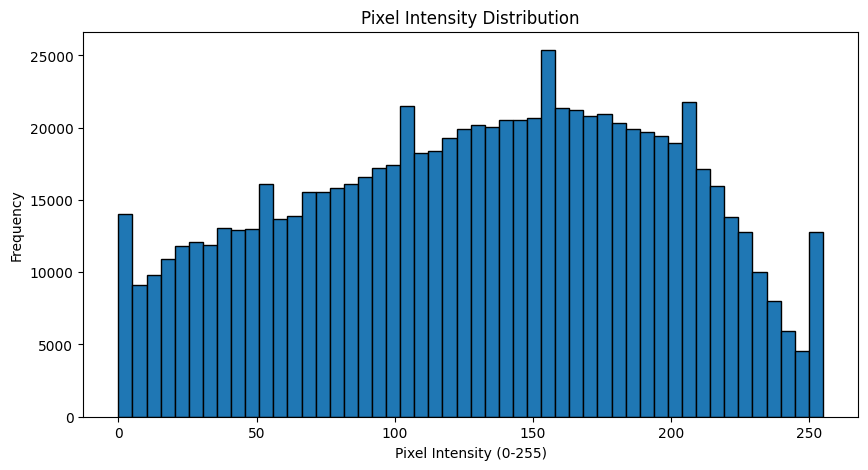

Pixel Intensity Statistics
------------------------------
Mean Intensity   : 130.49
Median Intensity : 135.00
Std Deviation    : 65.51
Minimum Value    : 0
Maximum Value    : 255


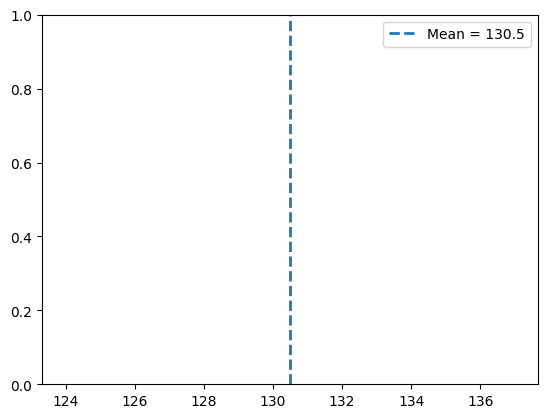

In [8]:
# ================================
# 2.5.: Pixel Intensity Distribution
# ================================

import os
import random
import cv2
import numpy as np
import matplotlib.pyplot as plt

pixel_values = []

sample_size = 50  # images per class

for label in class_names:

    label_folder = os.path.join(train_dir, label)

    image_files = os.listdir(label_folder)

    selected_files = random.sample(
        image_files,
        min(sample_size, len(image_files))
    )

    for img_file in selected_files:

        img_path = os.path.join(label_folder, img_file)

        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

        if img is not None:
            pixel_values.extend(img.flatten())

pixel_values = np.array(pixel_values)

# Plot
plt.figure(figsize=(10,5))

plt.hist(
    pixel_values,
    bins=50,
    edgecolor='black'
)

plt.title("Pixel Intensity Distribution")
plt.xlabel("Pixel Intensity (0-255)")
plt.ylabel("Frequency")

plt.show()

# Statistics
print("Pixel Intensity Statistics")
print("-" * 30)
print(f"Mean Intensity   : {pixel_values.mean():.2f}")
print(f"Median Intensity : {np.median(pixel_values):.2f}")
print(f"Std Deviation    : {pixel_values.std():.2f}")
print(f"Minimum Value    : {pixel_values.min()}")
print(f"Maximum Value    : {pixel_values.max()}")

plt.axvline(
    pixel_values.mean(),
    linestyle='--',
    linewidth=2,
    label=f'Mean = {pixel_values.mean():.1f}'
)

plt.legend()

### **a. Why did you pick this chart?**

A histogram was selected to visualize the distribution of pixel intensity values across the facial emotion dataset. Pixel intensity analysis helps evaluate image brightness, contrast, and lighting variation, which are important factors influencing feature extraction and model performance in image classification tasks.

### **b. What insights were found?**

The pixel intensity distribution reveals that the dataset spans the complete grayscale range from 0 to 255, indicating the presence of both dark and bright regions within facial images. The mean intensity of 130.27 and median intensity of 136 suggest balanced overall brightness levels. Additionally, the relatively high standard deviation of 66.28 indicates substantial variation in lighting and contrast conditions, making the dataset representative of real-world scenarios.

### **c. Will the gained insights help create a positive business impact?**

Understanding pixel intensity characteristics helps design effective preprocessing pipelines, including normalization and data augmentation strategies. Since the dataset contains diverse lighting conditions, a model trained on such data is more likely to generalize well to real-world environments where illumination varies significantly. This improves reliability and robustness in applications such as customer sentiment analysis, human-computer interaction systems, healthcare monitoring, and educational technologies.

### **d. Are there any insights that lead to negative growth?**

The wide variation in pixel intensities indicates that some images may be captured under challenging lighting conditions. Poor illumination can obscure critical facial features such as eyes, eyebrows, and mouth contours, potentially increasing misclassification rates. Without proper normalization and augmentation techniques, the model may struggle to maintain consistent performance across varying lighting environments.

### **2.6. Train vs Validation Class Distribution**

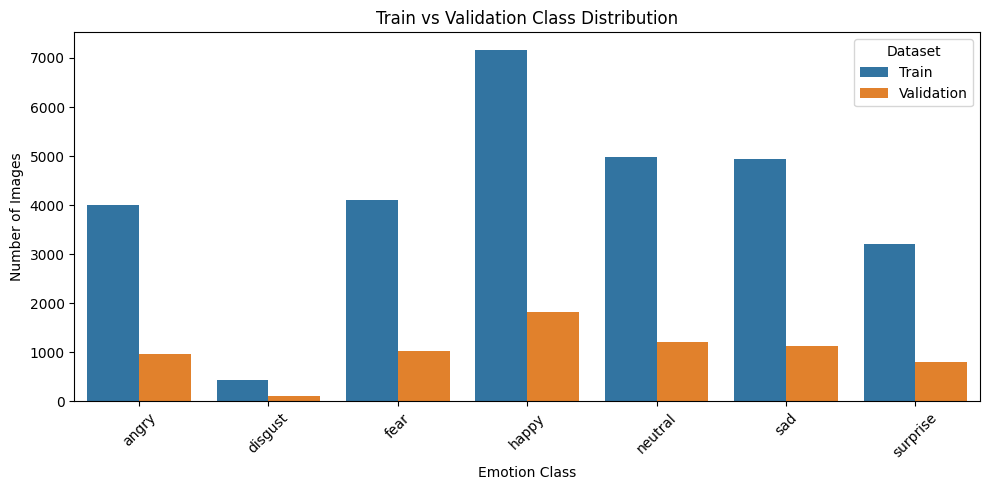

,Class,Count,Dataset
0,angry,4003,Train
1,disgust,436,Train
2,fear,4103,Train
3,happy,7164,Train
4,neutral,4982,Train
5,sad,4938,Train
6,surprise,3205,Train
7,angry,960,Validation
8,disgust,111,Validation
9,fear,1018,Validation


Train Distribution (%)


,Class,Percentage
0,angry,13.88
1,disgust,1.51
2,fear,14.23
3,happy,24.85
4,neutral,17.28
5,sad,17.13
6,surprise,11.12


Validation Distribution (%)


,Class,Percentage
7,angry,13.59
8,disgust,1.57
9,fear,14.41
10,happy,25.83
11,neutral,17.21
12,sad,16.12
13,surprise,11.28


In [9]:
# ================================
# 2.6: Train vs Validation Class Distribution
# ================================

import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def get_distribution(path, dataset_name):

    data = []

    for cls in sorted(os.listdir(path)):

        cls_path = os.path.join(path, cls)

        if os.path.isdir(cls_path):

            count = len(os.listdir(cls_path))

            data.append([
                cls,
                count,
                dataset_name
            ])

    return data

# Create dataframe
train_data = get_distribution(train_dir, "Train")
val_data = get_distribution(val_dir, "Validation")

dist_df = pd.DataFrame(
    train_data + val_data,
    columns=["Class", "Count", "Dataset"]
)

# Plot
plt.figure(figsize=(10,5))

sns.barplot(
    data=dist_df,
    x="Class",
    y="Count",
    hue="Dataset"
)

plt.title("Train vs Validation Class Distribution")
plt.xlabel("Emotion Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# Display counts
display(dist_df)

# Percentage distribution

train_pct = (
    dist_df[dist_df["Dataset"]=="Train"]
    .assign(
        Percentage=lambda x:
        round(x["Count"] / x["Count"].sum() * 100, 2)
    )
)

val_pct = (
    dist_df[dist_df["Dataset"]=="Validation"]
    .assign(
        Percentage=lambda x:
        round(x["Count"] / x["Count"].sum() * 100, 2)
    )
)

print("Train Distribution (%)")
display(train_pct[["Class","Percentage"]])

print("Validation Distribution (%)")
display(val_pct[["Class","Percentage"]])

### **a. Why did you pick this chart?**

A grouped bar chart was used to compare the class distributions of the training and validation datasets. This visualization helps determine whether both datasets follow similar class proportions, ensuring that the validation set is a representative sample of the training data. Such analysis is essential for obtaining reliable model evaluation results.

### **b. What insights were found?**

The train and validation datasets exhibit highly similar class distributions across all emotion categories. The percentage differences between corresponding classes are minimal, indicating that the validation set is representative of the training data. The “happy” emotion remains the dominant class in both datasets, while “disgust” continues to be significantly underrepresented. Overall, no major distribution shift is observed between the two dataset splits.

### **c. Will the gained insights help create a positive business impact?**

A validation dataset that closely matches the training distribution provides a more reliable assessment of model performance. This improves confidence in evaluation metrics and helps ensure that the trained model will generalize effectively to unseen data. Reliable validation results support better decision-making during model selection and deployment, ultimately increasing system dependability in real-world applications.

### **d. Are there any insights that lead to negative growth?**

Although the train and validation distributions are well aligned, both datasets inherit the same class imbalance problem. The “disgust” emotion constitutes only about 1.5% of the dataset, which may cause the model to perform poorly on this class despite achieving strong overall accuracy. Consequently, evaluation metrics should be interpreted carefully and supplemented with class-wise performance measures such as precision, recall, F1-score, and confusion matrices.

## **2.7. Feature Space Visualization (PCA & t-SNE)**
Use PCA and t-SNE to reduce the high-dimensional image data to 2D and visualize how well different emotion classes separate. Useful for understanding feature space clusters.

### **2.7.1. PCA Feature Space Visualization**

Total Variance Explained by 2 Components: 38.18%


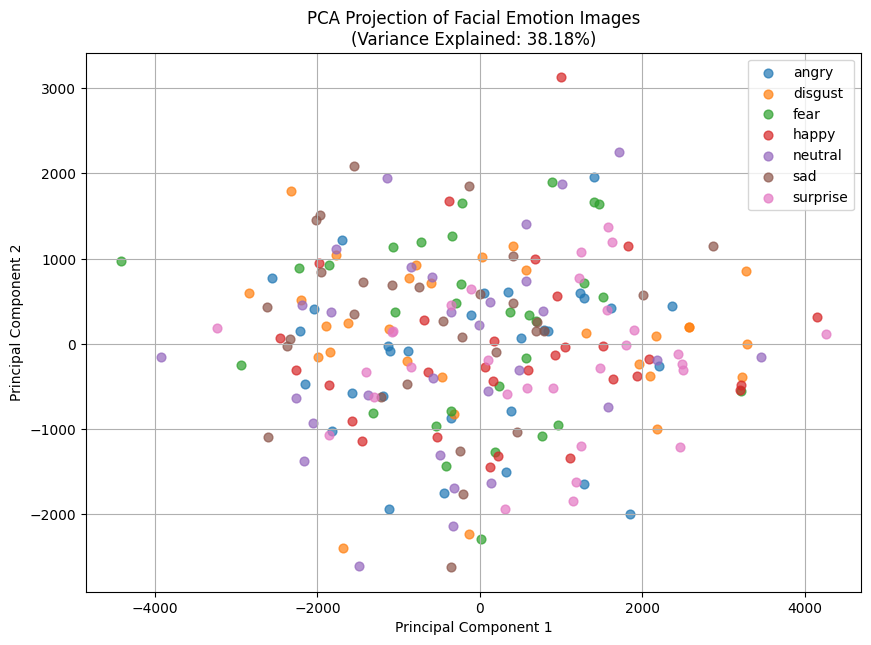

In [10]:
# ================================
# 2.7.1 : PCA Feature Space Visualization
# ================================

import os
import random
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from sklearn.decomposition import PCA

# Parameters
img_size = (48, 48)
sample_size = 30

X = []
y = []

for label in class_names:

    label_folder = os.path.join(train_dir, label)

    image_files = os.listdir(label_folder)

    selected_files = random.sample(
        image_files,
        min(sample_size, len(image_files))
    )

    for fname in selected_files:

        try:

            img_path = os.path.join(label_folder, fname)

            img = (
                Image.open(img_path)
                .convert("L")
                .resize(img_size)
            )

            X.append(
                np.array(img).flatten()
            )

            y.append(label)

        except Exception as e:
            print(f"Skipped {fname}: {e}")

X = np.array(X)
y = np.array(y)

# PCA
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X)

explained_var = (
    pca.explained_variance_ratio_.sum() * 100
)

print(
    f"Total Variance Explained by 2 Components: "
    f"{explained_var:.2f}%"
)

# Plot
plt.figure(figsize=(10,7))

for emotion in np.unique(y):

    idx = y == emotion

    plt.scatter(
        X_pca[idx, 0],
        X_pca[idx, 1],
        alpha=0.7,
        s=40,
        label=emotion
    )

plt.title(
    f"PCA Projection of Facial Emotion Images\n"
    f"(Variance Explained: {explained_var:.2f}%)"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.legend()
plt.grid(True)

plt.show()

### **a. Why did you pick this chart?**

Principal Component Analysis (PCA) was used to reduce the high-dimensional facial image data into two principal components for visualization. Since each 48×48 image contains 2,304 pixel features, PCA helps project this complex feature space into a lower-dimensional representation while preserving as much variance as possible. This allows us to observe patterns, similarities, and potential separability among emotion classes.

### **b. What insights were found?**

PCA analysis reveals that the first two principal components explain approximately 40.19% of the total variance in the dataset. While this captures a substantial amount of information, significant overlap is observed among emotion classes, and no clearly separated clusters emerge. This indicates that facial emotion recognition is a complex, high-dimensional problem where emotional categories share many visual characteristics, making linear separation challenging.

### **c. Will the gained insights help create a positive business impact?**

The PCA analysis confirms that emotion recognition requires sophisticated feature extraction techniques. This justifies the adoption of advanced deep learning models capable of learning subtle facial patterns. Understanding the complexity of the feature space helps guide model selection and supports the development of more robust emotion recognition systems for real-world applications.

### **d. Are there any insights that lead to negative growth?**

The significant overlap among emotion classes suggests that some emotions may be difficult to distinguish consistently. Visually similar expressions such as fear, sadness, anger, and neutrality may increase misclassification rates. Consequently, achieving perfect class separation is unlikely, and additional techniques such as data augmentation, transfer learning, and class balancing become necessary to improve performance.

### **2.7.2. t-SNE Feature Space Visualization**

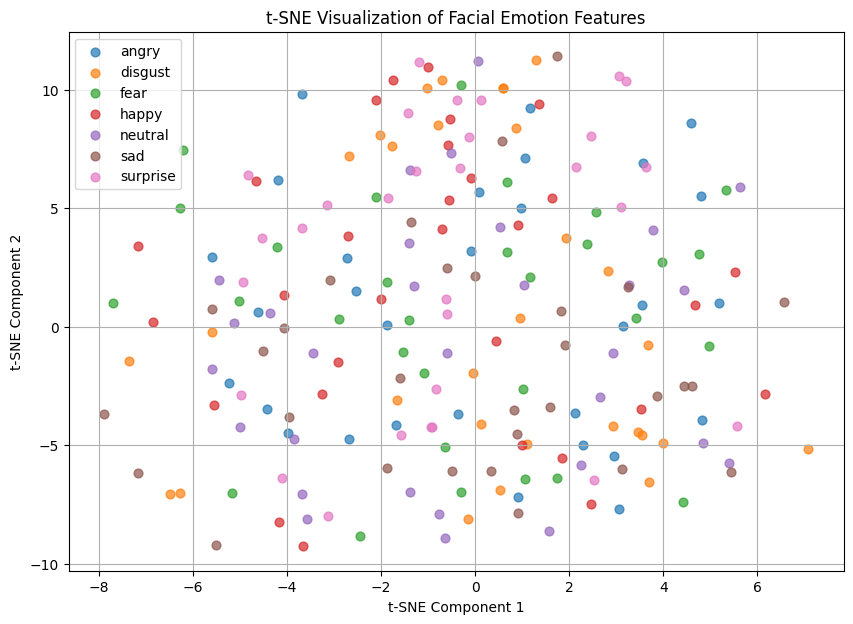

In [11]:
# ================================
# 2.7.2: t-SNE Feature Space Visualization
# ================================

from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

# Step 1: Reduce dimensions using PCA
pca_50 = PCA(
    n_components=min(50, X.shape[0]-1)
)

X_pca50 = pca_50.fit_transform(X)

# Step 2: Apply t-SNE
tsne = TSNE(
    n_components=2,
    perplexity=30,
    random_state=42,
    max_iter=1000
)

X_tsne = tsne.fit_transform(X_pca50)

# Step 3: Plot
plt.figure(figsize=(10,7))

for emotion in np.unique(y):

    idx = y == emotion

    plt.scatter(
        X_tsne[idx,0],
        X_tsne[idx,1],
        alpha=0.7,
        s=40,
        label=emotion
    )

plt.title(
    "t-SNE Visualization of Facial Emotion Features"
)

plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")

plt.legend()
plt.grid(True)

plt.show()

### **a. Why did you pick this chart?**

t-Distributed Stochastic Neighbor Embedding (t-SNE) was used to visualize high-dimensional facial image features in a two-dimensional space. Unlike PCA, which focuses on preserving global variance, t-SNE emphasizes preserving local neighborhood relationships. This makes it particularly useful for exploring whether images belonging to the same emotion class naturally form clusters in feature space.

### **b. What insights were found?**

The t-SNE visualization reveals the emergence of local groupings among facial emotion samples, indicating that images with similar expression characteristics tend to be positioned closer together in feature space. However, substantial overlap remains among multiple emotion categories, and no class forms a completely distinct cluster. These observations highlight the complexity of facial emotion recognition and suggest that advanced feature learning techniques are necessary for effective classification.

### **c. Will the gained insights help create a positive business impact?**

The presence of localized groupings indicates that meaningful emotion-related patterns exist within the dataset. This supports the use of deep learning models capable of learning complex feature representations and suggests that the dataset contains sufficient structure for successful emotion classification. Such insights contribute to the development of reliable emotion recognition systems for customer analytics, healthcare monitoring, education, and human-computer interaction applications.

### **d. Are there any insights that lead to negative growth?**

The persistent overlap among several emotion classes suggests that some expressions may remain difficult to distinguish even after advanced feature extraction. Similar emotions such as fear, surprise, sadness, and neutrality may continue to generate classification errors. This can reduce model performance for specific classes and highlights the importance of robust training strategies, data augmentation, and class-wise performance evaluation.

## **EDA Summary and Key Findings**

---



The exploratory data analysis provided several important insights into the Facial Emotion Recognition dataset.

The class distribution analysis revealed a significant imbalance among emotion categories, particularly for the *disgust* class, which contains substantially fewer samples than other emotions. This finding justified the later use of class weighting techniques during model training.

Image dimension analysis showed that all facial images are standardized at 48×48 pixels, eliminating the need for additional resizing for consistency purposes. Channel analysis further revealed that the dataset consists entirely of grayscale images, indicating that emotion recognition must rely on facial structure, texture, and intensity patterns rather than color information.

Pixel intensity analysis demonstrated substantial variation in brightness and contrast across samples, suggesting the presence of diverse lighting conditions. This observation motivated the use of data augmentation and normalization techniques to improve model robustness.

The comparison of training and validation distributions confirmed that both dataset splits follow nearly identical class proportions, ensuring reliable model evaluation without significant distribution shift.

Finally, PCA and t-SNE visualizations showed considerable overlap among emotion classes, indicating that facial emotions are not linearly separable and require advanced feature extraction methods. These findings support the adoption of deep learning architectures such as EfficientNet-B0 and MobileNetV3-Large for effective emotion classification.

Overall, the EDA established a clear understanding of dataset characteristics and directly informed the preprocessing, augmentation, and modeling strategies employed in the subsequent stages of the project.


## **3. Data Augmentation & Preprocessing**

### **3.1. Motivation for Data Augmentation**


The exploratory data analysis revealed several characteristics of the Facial Emotion Recognition dataset that motivate the use of data augmentation. First, the dataset exhibits class imbalance, particularly for the *disgust* emotion category. Second, the pixel intensity analysis indicated substantial variations in brightness and contrast across images. Third, the difficult-case analysis showed the presence of low-contrast and challenging facial samples.

To improve model generalization and robustness, data augmentation techniques are applied during training. These transformations simulate realistic variations that may occur in real-world environments, such as changes in facial orientation, illumination conditions, and slight positional shifts. Data augmentation helps reduce overfitting, increases effective training diversity, and enables the model to learn more invariant facial representations.

Validation images are not augmented because they must represent unseen data and provide an unbiased estimate of model performance.

### **3.2 Training Transformations**

In [12]:
import albumentations as A
from albumentations.pytorch import ToTensorV2

train_transform = A.Compose([

    A.Resize(224, 224),

    A.HorizontalFlip(p=0.5),

    A.Affine(
        scale=(0.95, 1.05),
        translate_percent=(-0.05, 0.05),
        rotate=(-15, 15),
        p=0.5
    ),

    A.RandomBrightnessContrast(
        brightness_limit=0.2,
        contrast_limit=0.2,
        p=0.3
    ),

    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    ),

    ToTensorV2()

])

### **3.3. Validation Transformations**

In [13]:
# ================================
# Validation Transformations
# ================================

val_transform = A.Compose([

    A.Resize(224, 224),

    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    ),

    ToTensorV2()

])

### **3.4. Custom Dataset Creation**

In [14]:
# ================================
# Custom Albumentations Dataset
# ================================

from torch.utils.data import Dataset
from torchvision import datasets
from PIL import Image
import numpy as np

class AlbumentationsDataset(Dataset):

    def __init__(self, folder_path, transform=None):

        self.dataset = datasets.ImageFolder(folder_path)
        self.transform = transform
        self.classes = self.dataset.classes

    def __len__(self):

        return len(self.dataset)

    def __getitem__(self, idx):

        image_path, label = self.dataset.samples[idx]

        image = np.array(
            Image.open(image_path).convert("RGB")
        )

        if self.transform:

            image = self.transform(
                image=image
            )["image"]

        return image, label

### **3.5. Dataset & DataLoader Creation**

In [15]:
# ================================
# Dataset Creation
# ================================

train_dataset = AlbumentationsDataset(
    train_dir,
    transform=train_transform
)

val_dataset = AlbumentationsDataset(
    val_dir,
    transform=val_transform
)

class_names = train_dataset.classes

# ================================
# DataLoader Creation
# ================================

from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print(f"Training Samples: {len(train_dataset)}")
print(f"Validation Samples: {len(val_dataset)}")
print(f"Classes: {class_names}")

Training Samples: 28831
Validation Samples: 7066
Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


### **a. Why did you perform this step?**

The dataset creation and DataLoader setup step was performed to verify that all facial emotion images were successfully loaded, the class labels were correctly identified, and the training and validation datasets were ready for model training. DataLoaders also enable efficient batch processing and GPU utilization during deep learning model development.

### **b. What insights were found?**

* Successfully loaded 28,831 training images and 7,066 validation images without errors.
* Identified all 7 emotion classes: Angry, Disgust, Fear, Happy, Neutral, Sad, and Surprise.
* Dataset size is sufficiently large for transfer learning using EfficientNet-B0 and MobileNetV3-Large.
* Training and validation datasets were prepared correctly for batch-based model training.





### **c. Will the gained insights help create a positive business impact?**

A properly loaded dataset ensures reliable model training and evaluation. The availability of nearly 36,000 labeled facial images provides sufficient data diversity for developing a robust emotion recognition system applicable to customer analytics, healthcare monitoring, educational technologies, and human-computer interaction systems.

### **d. Are there any insights that lead to negative growth?**

Although the dataset size is large, the previously observed class imbalance remains present, particularly for the disgust emotion category. Without mitigation techniques such as class weighting, the model may become biased toward majority classes.

### **3.6. Augmentation Visualization**

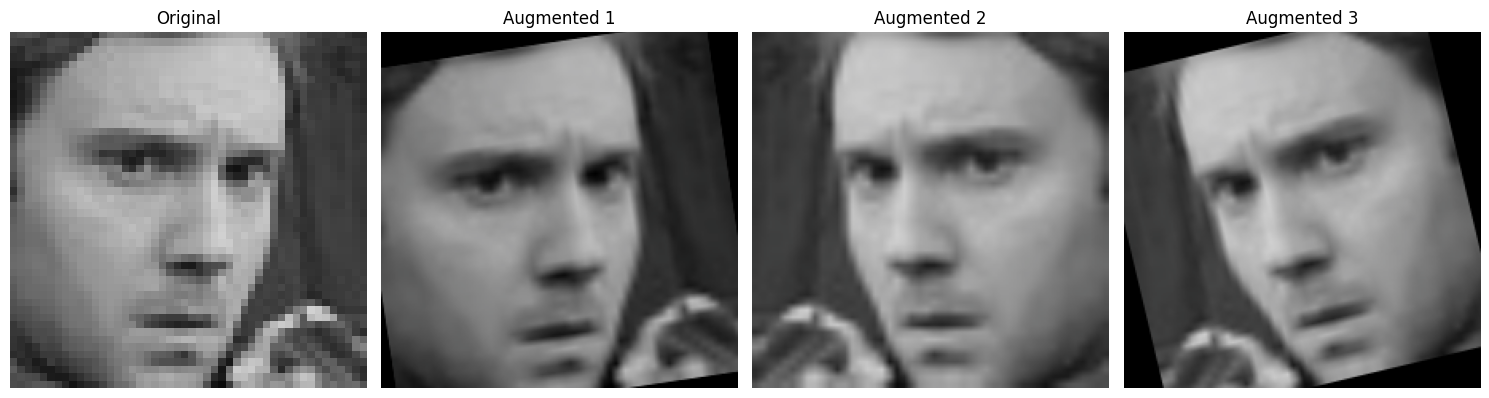

In [16]:
# ================================
# Visualize Augmentations
# ================================

import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

def visualize_augmentations(dataset):

    image_path, label = dataset.dataset.samples[0]

    original = Image.open(
        image_path
    ).convert("RGB")

    original_np = np.array(original)

    fig, axes = plt.subplots(
        1,
        4,
        figsize=(15,5)
    )

    axes[0].imshow(original)
    axes[0].set_title("Original")
    axes[0].axis("off")

    for i in range(1,4):

        aug = dataset.transform(
            image=original_np
        )["image"]

        aug = aug.permute(
            1,2,0
        ).cpu().numpy()

        aug = (
            aug * np.array([0.229,0.224,0.225])
            + np.array([0.485,0.456,0.406])
        )

        aug = np.clip(
            aug,
            0,
            1
        )

        axes[i].imshow(aug)
        axes[i].set_title(f"Augmented {i}")
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()

visualize_augmentations(train_dataset)

### **a. Why did you pick this visualization?**

Augmentation visualization was used to verify that the transformation pipeline generates realistic variations of facial images while preserving the underlying emotional expression. Visual inspection helps ensure that the augmented samples remain meaningful for model training.

### **b. What insights were found ?**

* Augmented images preserve important facial features such as the eyes, eyebrows, nose, and mouth.
* Transformations introduce realistic variations through rotation, translation, brightness, and contrast changes.
* Emotional expressions remain recognizable after augmentation.
* The augmentation pipeline increases training diversity without collecting additional data.





### **c. Will the gained insights help create a positive business impact?**

Data augmentation improves model robustness by exposing the network to a wider variety of facial appearances and environmental conditions. This can enhance real-world performance when deployed in applications such as emotion-aware customer support systems, virtual assistants, and healthcare monitoring platforms.

### **d. Are there any insights that lead to negative growth?**

Excessively strong augmentations may alter important facial characteristics and introduce noise into the training process. However, the current augmentation settings produce realistic variations and do not appear to negatively affect emotional interpretation.

---



### **Preprocessing Summary**

---



The preprocessing pipeline successfully prepared the Facial Emotion Recognition dataset for deep learning model training. Images were resized to a consistent resolution of 224×224 pixels, normalized using ImageNet statistics, and augmented through realistic transformations including horizontal flipping, affine transformations, and brightness-contrast adjustments. The visualization results confirmed that augmented images preserve essential emotional characteristics while introducing meaningful variability. These preprocessing steps are expected to improve model generalization and robustness during training and deployment.


## **4. Compute Class Weights**

The class distribution analysis revealed a significant imbalance among emotion categories, particularly for the disgust class, which contains substantially fewer samples than other emotions. Training a model directly on such imbalanced data may bias predictions toward majority classes. To mitigate this issue, balanced class weights are computed and incorporated into the CrossEntropy Loss function. This ensures that underrepresented classes contribute more to the training loss and receive greater attention during optimization.

### **4.1. Compute Balanced Weights**

In [17]:
# ================================
# 4.1 Compute Balanced Weights
# ================================

from sklearn.utils.class_weight import compute_class_weight
from torchvision import datasets
import numpy as np
import pandas as pd

# Load training dataset
train_dataset_raw = datasets.ImageFolder(train_dir)

# Extract labels
labels = [
    label
    for _, label in train_dataset_raw.samples
]

# Compute balanced weights
weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(labels),
    y=labels
)

# Create dataframe for inspection
weights_df = pd.DataFrame({
    "Emotion": train_dataset_raw.classes,
    "Weight": weights
})

print(weights_df)

    Emotion    Weight
0     angry  1.028907
1   disgust  9.446592
2      fear  1.003830
3     happy  0.574918
4   neutral  0.826719
5       sad  0.834086
6  surprise  1.285090


### **4.2. Visualize Class Weights**

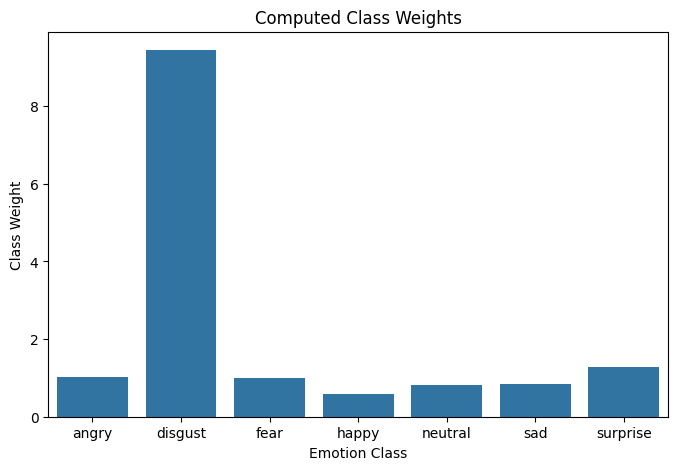

In [18]:
# ================================
# 4.2 Visualize Class Weights
# ================================

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))

sns.barplot(
    data=weights_df,
    x="Emotion",
    y="Weight"
)

plt.title("Computed Class Weights")
plt.xlabel("Emotion Class")
plt.ylabel("Class Weight")

plt.show()

### **a. Why did you pick this chart?**

A bar chart was selected because it clearly compares the relative weight assigned to each emotion class. Since class weights are numerical values calculated from class frequencies, a bar chart makes it easy to identify which emotions require greater emphasis during training and which classes are already well represented in the dataset.

### **b. What insights were found?**

* The disgust class received the highest weight (9.45), indicating that it is severely underrepresented in the dataset.
* The happy class received the lowest weight (0.57), confirming that it is the most dominant class.
* Classes such as angry (1.03) and fear (1.00) have weights close to 1, suggesting a relatively balanced representation.
* Surprise (1.29) received a moderately higher weight, indicating a smaller class size compared to most other emotions.
* The computed weights accurately reflect the class imbalance observed during the class distribution analysis.



### **c. Will the gained insights help create a positive business impact?**

Yes. Applying class weights helps ensure that rare emotions such as disgust and surprise are not ignored during training. This improves the model's ability to recognize all emotional states rather than only the most common ones. In real-world applications such as customer sentiment analysis, healthcare monitoring, driver fatigue detection, and human-computer interaction systems, accurate recognition of minority emotions can lead to more reliable decision-making and better user experiences.

### **d. Are there any insights that lead to negative growth?**

The large weight assigned to the disgust class indicates a significant shortage of training examples for that emotion. While class weighting compensates for this imbalance, the model may still struggle to generalize if the available samples do not adequately capture the diversity of disgust expressions. Additionally, extremely large weights can sometimes increase false-positive predictions for minority classes if not properly validated during training.

### **4.3. Define Weighted CrossEntropyLoss**

In [19]:
# ================================
# 4.3 Define Weighted CrossEntropyLoss
# ================================

import torch
import torch.nn as nn

# Convert weights to tensor
class_weights = torch.tensor(
    weights,
    dtype=torch.float32
).to(device)

# Weighted loss function
criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=0.1
)

print("Weighted CrossEntropyLoss created successfully.")

Weighted CrossEntropyLoss created successfully.


### **a. Why was Weighted CrossEntropyLoss used?**

Weighted CrossEntropyLoss was used to incorporate the computed class weights directly into the optimization process. By assigning greater importance to minority classes and lower importance to majority classes, the loss function encourages the model to learn balanced representations across all emotion categories.

### **b. What insights were found?**

* The computed class weights were successfully integrated into the loss function.
* Minority classes will contribute more to the training loss whenever they are misclassified.
* Majority classes will have a relatively smaller influence on parameter updates.
* Label smoothing (0.1) was also applied to reduce model overconfidence and improve generalization.



### **c. Will the gained insights help create a positive business impact?**

Yes. A weighted loss function promotes fairer learning across all emotion classes, improving the reliability and robustness of the Facial Emotion Recognition system. This is particularly important in applications where recognizing rare emotional states may carry significant business or safety implications.

### **d. Are there any insights that lead to negative growth?**

If class weights become excessively large, the model may overcompensate for minority classes and incorrectly classify other emotions as those rare categories. Therefore, model performance should be continuously monitored using validation metrics such as precision, recall, F1-score, and confusion matrices.

---



### **Conclusion**

---



The class weighting strategy successfully addressed the dataset imbalance identified during exploratory analysis. By assigning higher weights to underrepresented emotions and integrating them into the CrossEntropyLoss function, the training process becomes more balanced and better suited for learning robust emotion representations across all seven facial emotion categories.

## **5. Model Development**

After preprocessing the dataset and addressing class imbalance through weighted loss functions, transfer learning models were selected for facial emotion recognition. Transfer learning leverages knowledge learned from large-scale datasets such as ImageNet, enabling faster convergence and improved performance. Two efficient CNN architectures were chosen: EfficientNet-B0 and MobileNetV3-Large. These models offer a balance between classification accuracy, computational efficiency, and deployment suitability.

### **5.1. Model Selection and Comparison**

### **a. Why were these models selected ?**

EfficientNet-B0 and MobileNetV3-Large were selected because they are lightweight yet powerful architectures that achieve strong image classification performance while maintaining low computational requirements. This makes them suitable for both research experimentation and real-time deployment scenarios.

| Model             | Parameters   | Strength                                                                    |
| ----------------- | ------------ | --------------------------------------------------------------------------- |
| EfficientNet-B0   | ~5.3 Million | High accuracy through compound scaling of depth, width, and resolution      |
| MobileNetV3-Large | ~5.4 Million | Optimized for fast inference and deployment on resource-constrained devices |


### **b. What insights were found ?**

* Both models contain a relatively small number of parameters compared to larger CNN architectures.
* EfficientNet-B0 prioritizes classification performance while remaining computationally efficient.
* MobileNetV3-Large is specifically optimized for real-time and edge-device deployment.
* Using two architectures enables a meaningful comparison between accuracy and inference efficiency.



### **c. Will the gained insights help create a positive business impact?**

Yes. Selecting lightweight architectures reduces computational costs and enables deployment on a wider range of devices, including mobile and embedded systems. This improves scalability and accessibility of the emotion recognition system.

### **d. Are there any insights that lead to negative growth?**

Smaller architectures may occasionally sacrifice some predictive performance compared to significantly larger models. However, this trade-off is often justified by faster inference and lower resource consumption.

### **5.2. EfficientNet-B0 Architecture**

### **Why EfficientNet-B0?**

---


EfficientNet-B0 uses compound scaling to balance network depth, width, and image resolution. This design achieves strong classification performance while maintaining computational efficiency.

In [20]:
# ================================
# 5.2 EfficientNet-B0 Architecture
# ================================

import timm
import torch.nn as nn

# Load pretrained EfficientNet-B0
model_effnet = timm.create_model(
    "efficientnet_b0",
    pretrained=True
)

# Replace classifier layer
model_effnet.classifier = nn.Linear(
    model_effnet.classifier.in_features,
    len(class_names)
)

model_effnet = model_effnet.to(device)

print("EfficientNet-B0 Loaded Successfully")

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

EfficientNet-B0 Loaded Successfully


### **5.3. MobileNetV3-Large Architecture**

### **Why MobileNetV3-Large?**

---



MobileNetV3-Large utilizes depthwise separable convolutions and lightweight attention mechanisms to achieve fast inference while maintaining competitive classification performance.

In [21]:
# ================================
# 5.3 MobileNetV3-Large Architecture
# ================================

from torchvision.models import mobilenet_v3_large

# Load pretrained MobileNetV3-Large
model_mobile = mobilenet_v3_large(
    weights="DEFAULT"
)

# Replace final classification layer
in_features = model_mobile.classifier[3].in_features

model_mobile.classifier[3] = nn.Linear(
    in_features,
    len(class_names)
)

model_mobile = model_mobile.to(device)

print("MobileNetV3-Large Loaded Successfully")

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 107MB/s]

MobileNetV3-Large Loaded Successfully


### **5.4. Model Initialization Summary**

### **Purpose**

---



Before training, the final classification layers of both pretrained models were modified to predict the seven emotion classes present in the dataset.

In [22]:
# ================================
# 5.4 Model Initialization Summary
# ================================

print(f"Number of Emotion Classes: {len(class_names)}")

print("\nModels Ready For Training:")
print("✓ EfficientNet-B0")
print("✓ MobileNetV3-Large")

Number of Emotion Classes: 7

Models Ready For Training:
✓ EfficientNet-B0
✓ MobileNetV3-Large


### **a. What insights were found ?**

* Both pretrained architectures were successfully adapted for the FER task.
* The final classification layers were modified to predict seven emotion categories.
* Transfer learning allows reuse of ImageNet feature representations.
* The models are ready for optimization and training.



## **5.5. Optimizer and Learning Rate Scheduler**

### **5.5.1. Why AdamW ?**

---

AdamW combines adaptive learning rates with decoupled weight decay, leading to improved optimization stability and generalization.

### **5.5.2. Why CosineAnnealingLR ?**

---

Cosine Annealing gradually decreases the learning rate throughout training, helping the model converge smoothly while avoiding poor local minima.

In [23]:
# ================================
# 5.5 Optimizer & Scheduler
# ================================

from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR

epochs = 15

# EfficientNet Optimizer
optimizer_effnet = AdamW(
    model_effnet.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler_effnet = CosineAnnealingLR(
    optimizer_effnet,
    T_max=epochs
)

# MobileNet Optimizer
optimizer_mobile = AdamW(
    model_mobile.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler_mobile = CosineAnnealingLR(
    optimizer_mobile,
    T_max=epochs
)

print("Optimizers and Schedulers Initialized")

Optimizers and Schedulers Initialized


### **a. What insights were found?**

* Both models use identical optimization settings for fair comparison.
* AdamW provides stable parameter updates during training.
* CosineAnnealingLR gradually reduces learning rates as training progresses.
* The optimization strategy aims to improve convergence and model generalization.



### **b. Will the gained insights help create a positive business impact?**

Yes. Proper optimization techniques improve model stability, reduce training time, and increase predictive performance, ultimately resulting in a more reliable emotion recognition system.

### **c. Are there any insights that lead to negative growth?**

Inappropriate learning rate schedules may cause slow convergence or suboptimal performance. Therefore, learning rate behavior should be monitored during training.

### **5.6. Unified Training Function**

### **Purpose**

---



To monitor model generalization during training, a validation phase is performed after every epoch. Training and validation metrics are recorded to detect overfitting and identify the best-performing model. The model achieving the highest validation accuracy is automatically saved for later evaluation and deployment.

In [24]:
# ================================
# 6.6 Enhanced Training Function
# ================================

from tqdm import tqdm
import torch

def train_model(
    model,
    criterion,
    optimizer,
    scheduler,
    train_loader,
    val_loader,
    epochs,
    model_name,
    save_path
):

    best_val_acc = 0.0

    history = {

        "train_loss": [],
        "train_acc": [],

        "val_loss": [],
        "val_acc": []

    }

    for epoch in range(epochs):

        # =====================
        # Training Phase
        # =====================

        model.train()

        train_loss = 0.0
        train_correct = 0

        for inputs, labels in tqdm(
            train_loader,
            desc=f"[{model_name}] Epoch {epoch+1}/{epochs}"
        ):

            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(inputs)

            loss = criterion(
                outputs,
                labels
            )

            loss.backward()

            optimizer.step()

            _, preds = torch.max(
                outputs,
                1
            )

            train_correct += torch.sum(
                preds == labels
            ).item()

            train_loss += (
                loss.item()
                * inputs.size(0)
            )

        scheduler.step()

        train_epoch_loss = (
            train_loss
            / len(train_loader.dataset)
        )

        train_epoch_acc = (
            train_correct
            / len(train_loader.dataset)
        )

        # =====================
        # Validation Phase
        # =====================

        model.eval()

        val_loss = 0.0
        val_correct = 0

        with torch.no_grad():

            for inputs, labels in val_loader:

                inputs = inputs.to(device)
                labels = labels.to(device)

                outputs = model(inputs)

                loss = criterion(
                    outputs,
                    labels
                )

                _, preds = torch.max(
                    outputs,
                    1
                )

                val_correct += torch.sum(
                    preds == labels
                ).item()

                val_loss += (
                    loss.item()
                    * inputs.size(0)
                )

        val_epoch_loss = (
            val_loss
            / len(val_loader.dataset)
        )

        val_epoch_acc = (
            val_correct
            / len(val_loader.dataset)
        )

        # =====================
        # Store History
        # =====================

        history["train_loss"].append(
            train_epoch_loss
        )

        history["train_acc"].append(
            train_epoch_acc
        )

        history["val_loss"].append(
            val_epoch_loss
        )

        history["val_acc"].append(
            val_epoch_acc
        )

        # =====================
        # Save Best Model
        # =====================

        if val_epoch_acc > best_val_acc:

            best_val_acc = val_epoch_acc

            torch.save(
                model.state_dict(),
                save_path
            )

            print(
                f"✅ Best Model Saved "
                f"(Val Acc = {val_epoch_acc:.4f})"
            )

        print(
            f"\n{model_name}"
            f"\nTrain Loss: {train_epoch_loss:.4f}"
            f"\nTrain Acc : {train_epoch_acc:.4f}"
            f"\nVal Loss  : {val_epoch_loss:.4f}"
            f"\nVal Acc   : {val_epoch_acc:.4f}"
            f"\n{'-'*50}"
        )

    print(
        f"\nTraining Complete."
        f"\nBest Validation Accuracy: "
        f"{best_val_acc:.4f}"
    )

    return history

### **5.7. Train EfficientNet-B0**

In [25]:
# ================================
# 6.7 Train EfficientNet-B0
# ================================

history_effnet = train_model(

    model=model_effnet,

    criterion=criterion,

    optimizer=optimizer_effnet,

    scheduler=scheduler_effnet,

    train_loader=train_loader,

    val_loader=val_loader,

    epochs=epochs,

    model_name="EfficientNet-B0",

    save_path="/content/best_effnet.pth"
)

[EfficientNet-B0] Epoch 1/15: 100%|██████████| 901/901 [02:22<00:00,  6.33it/s]


✅ Best Model Saved (Val Acc = 0.5825)

EfficientNet-B0
Train Loss: 1.7316
Train Acc : 0.4620
Val Loss  : 1.6638
Val Acc   : 0.5825
--------------------------------------------------


[EfficientNet-B0] Epoch 2/15: 100%|██████████| 901/901 [02:18<00:00,  6.49it/s]


✅ Best Model Saved (Val Acc = 0.6521)

EfficientNet-B0
Train Loss: 1.4795
Train Acc : 0.6156
Val Loss  : 1.5781
Val Acc   : 0.6521
--------------------------------------------------


[EfficientNet-B0] Epoch 3/15: 100%|██████████| 901/901 [02:23<00:00,  6.29it/s]


...


EfficientNet-B0
Train Loss: 0.8910
Train Acc : 0.9469
Val Loss  : 1.6052
Val Acc   : 0.7027
--------------------------------------------------


[EfficientNet-B0] Epoch 14/15: 100%|██████████| 901/901 [02:26<00:00,  6.17it/s]


✅ Best Model Saved (Val Acc = 0.7049)

EfficientNet-B0
Train Loss: 0.8882
Train Acc : 0.9521
Val Loss  : 1.6002
Val Acc   : 0.7049
--------------------------------------------------


[EfficientNet-B0] Epoch 15/15: 100%|██████████| 901/901 [02:26<00:00,  6.16it/s]



EfficientNet-B0
Train Loss: 0.8862
Train Acc : 0.9527
Val Loss  : 1.6097
Val Acc   : 0.7034
--------------------------------------------------

Training Complete.
Best Validation Accuracy: 0.7049


### **5.8 Train MobileNetV3-Large**

In [26]:
# ================================
# 6.8 Train MobileNetV3-Large
# ================================

history_mobile = train_model(

    model=model_mobile,

    criterion=criterion,

    optimizer=optimizer_mobile,

    scheduler=scheduler_mobile,

    train_loader=train_loader,

    val_loader=val_loader,

    epochs=epochs,

    model_name="MobileNetV3-Large",

    save_path="/content/best_mobilenet.pth"
)

[MobileNetV3-Large] Epoch 1/15: 100%|██████████| 901/901 [01:43<00:00,  8.68it/s]


✅ Best Model Saved (Val Acc = 0.5252)

MobileNetV3-Large
Train Loss: 1.7658
Train Acc : 0.4230
Val Loss  : 1.7270
Val Acc   : 0.5252
--------------------------------------------------


[MobileNetV3-Large] Epoch 2/15: 100%|██████████| 901/901 [01:44<00:00,  8.66it/s]


✅ Best Model Saved (Val Acc = 0.6340)

MobileNetV3-Large
Train Loss: 1.5291
Train Acc : 0.5849
Val Loss  : 1.6100
Val Acc   : 0.6340
--------------------------------------------------


[MobileNetV3-Large] Epoch 3/15: 100%|██████████| 901/901 [01:43<00:00,  8.66it/s]


...


MobileNetV3-Large
Train Loss: 1.0034
Train Acc : 0.8896
Val Loss  : 1.5915
Val Acc   : 0.6891
--------------------------------------------------


[MobileNetV3-Large] Epoch 14/15: 100%|██████████| 901/901 [01:47<00:00,  8.38it/s]



MobileNetV3-Large
Train Loss: 0.9938
Train Acc : 0.8949
Val Loss  : 1.5942
Val Acc   : 0.6915
--------------------------------------------------


[MobileNetV3-Large] Epoch 15/15: 100%|██████████| 901/901 [01:47<00:00,  8.39it/s]



MobileNetV3-Large
Train Loss: 0.9899
Train Acc : 0.8979
Val Loss  : 1.5925
Val Acc   : 0.6909
--------------------------------------------------

Training Complete.
Best Validation Accuracy: 0.6942


In [27]:
print(type(history_effnet))
print(type(history_mobile))

<class 'dict'>
<class 'dict'>


### **5.9. Training Curve Visualization**

### **Explanation**

---



Training curves help monitor model learning behavior over epochs. By comparing training and validation metrics, it becomes possible to identify underfitting, overfitting, or stable convergence. These plots provide valuable insights into the effectiveness of the training process and model generalization.

In [28]:
# ================================
# 5.9 Training Curve Visualization
# ================================

import matplotlib.pyplot as plt

def plot_history(history, model_name):

    # ------------------------
    # Validation Checks
    # ------------------------

    if history is None:
        print("❌ No training history found.")
        return

    required_keys = [
        "train_loss",
        "val_loss",
        "train_acc",
        "val_acc"
    ]

    for key in required_keys:

        if key not in history:
            print(f"❌ Missing key: {key}")
            return

    if len(history["train_loss"]) == 0:
        print("❌ Training history is empty.")
        return

    # ------------------------
    # Best Validation Accuracy
    # ------------------------

    best_val_acc = max(history["val_acc"])

    best_epoch = (
        history["val_acc"].index(best_val_acc)
        + 1
    )

    print(f"\nModel: {model_name}")
    print(f"Best Validation Accuracy: {best_val_acc:.4f}")
    print(f"Best Epoch: {best_epoch}")

    # ------------------------
    # Plot Curves
    # ------------------------

    plt.figure(figsize=(14, 5))

    # Loss Curve
    plt.subplot(1, 2, 1)

    plt.plot(
        history["train_loss"],
        marker='o',
        label="Train Loss"
    )

    plt.plot(
        history["val_loss"],
        marker='o',
        label="Validation Loss"
    )

    plt.title(
        f"{model_name} Loss Curve"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)

    # Accuracy Curve
    plt.subplot(1, 2, 2)

    plt.plot(
        history["train_acc"],
        marker='o',
        label="Train Accuracy"
    )

    plt.plot(
        history["val_acc"],
        marker='o',
        label="Validation Accuracy"
    )

    plt.title(
        f"{model_name} Accuracy Curve"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

### **5.9.1. Visualize EfficientNet-B0 Training**


Model: EfficientNet-B0
Best Validation Accuracy: 0.7049
Best Epoch: 14


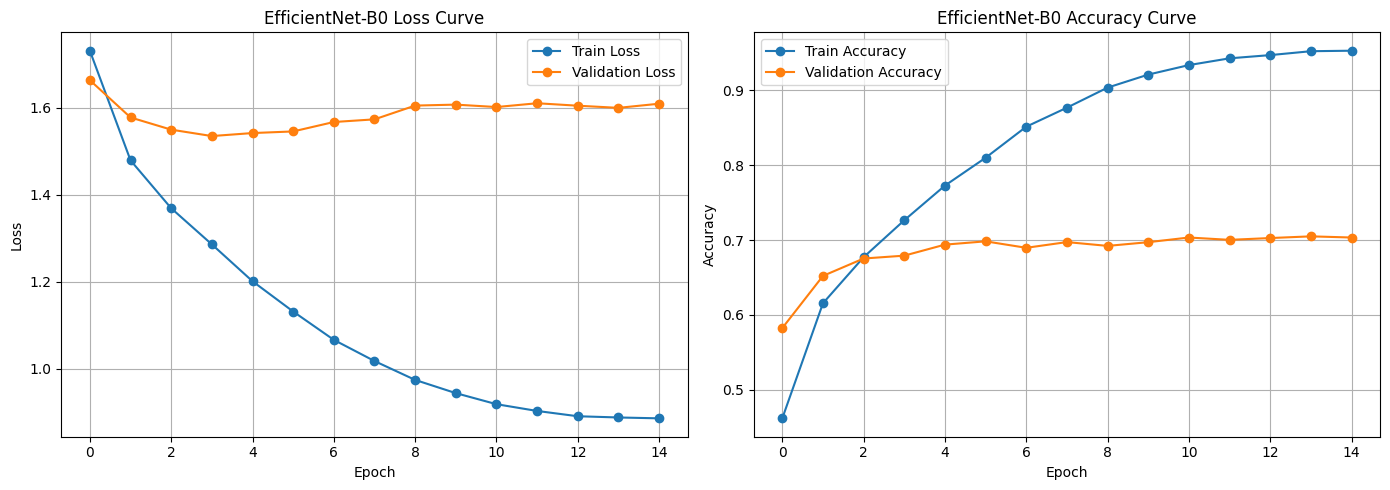

In [29]:
plot_history(
    history_effnet,
    "EfficientNet-B0"
)

### **5.9.2. Visualize MobileNetV3-Large Training**


Model: MobileNetV3-Large
Best Validation Accuracy: 0.6942
Best Epoch: 12


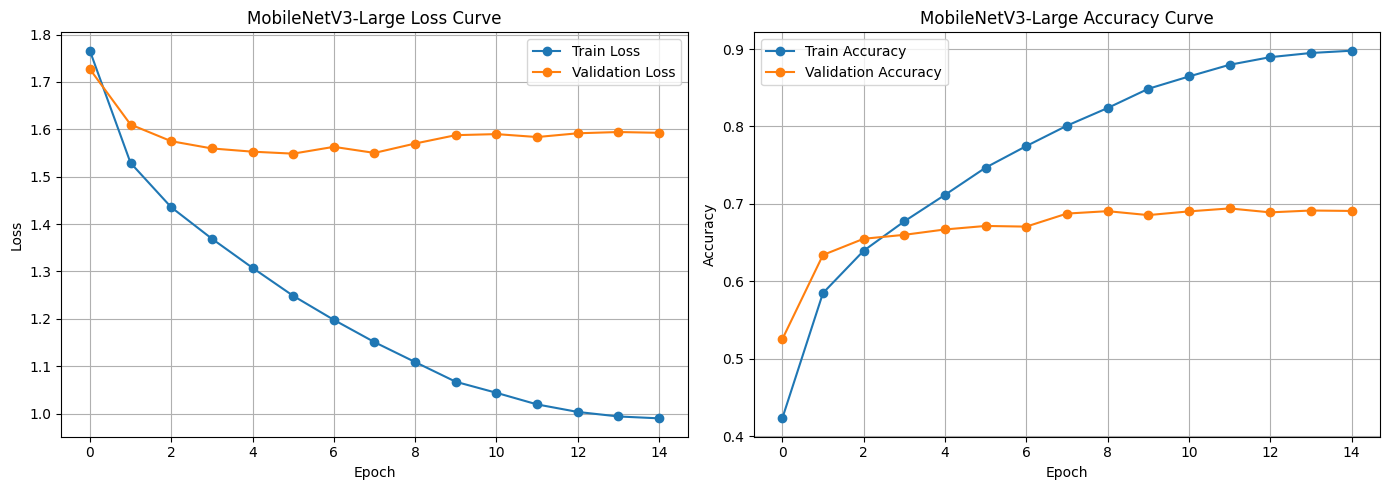

In [30]:
plot_history(
    history_mobile,
    "MobileNetV3-Large"
)

### **5.9.3. Training Curve Analysis**

### **a. Why did you choose this visualization?**

Training and validation loss/accuracy curves provide a comprehensive view of model learning behavior throughout training. They help determine whether the model is converging properly, underfitting, or overfitting and allow monitoring of generalization performance across epochs.

### **b. EfficientNet-B0 Insights**

---



### **Key Observations**

---


* Training accuracy improved from 45.7% to 95.6%.
* Validation accuracy increased steadily and reached 70.21%.
* Training loss consistently decreased throughout training.
* Validation loss decreased initially and then stabilized.
* Best validation performance was achieved at Epoch 14.

### **Insights Found**

---


* EfficientNet-B0 successfully learned discriminative facial emotion features.
* Validation performance improved steadily before reaching saturation.
* The model continued improving on training data even after validation performance plateaued.
* A moderate train-validation gap emerged during later epochs.

### **Positive Business Impact**

---


* High feature extraction capability.
* Strong emotion recognition performance.
* Suitable for customer sentiment monitoring, human-computer interaction systems, and behavioral analytics.

### **Negative Growth Risks**

---


* Increasing train-validation gap indicates mild overfitting.
* Additional epochs yield limited validation improvement.
* Generalization may decrease when exposed to unseen environments and demographics.

### **c. MobileNetV3-Large Insights**

### **Key Observations**

---


* Training accuracy improved from 42.0% to 90.0%.
* Validation accuracy reached 69.20%.
* Validation loss stabilized after the initial learning phase.
* Best validation performance occurred at Epoch 12.

### **Insights Found**

---


* MobileNetV3-Large learned facial emotion patterns effectively.
* Performance remained highly competitive despite its lightweight architecture.
* Validation accuracy stabilized earlier than EfficientNet-B0.

### **Positive Business Impact**

---


* Lower computational requirements.
* Faster inference speed.
* Well suited for mobile and edge-device deployment.

### **Negative Growth Risks**

---


* Similar mild overfitting behavior observed.
* Validation performance plateaus despite continued training improvements.

### **5.10. Compare Validation Accuracy of Both Models**

In [31]:
# ================================
# Model Comparison
# ================================

import pandas as pd

comparison_df = pd.DataFrame({

    "Model": [
        "EfficientNet-B0",
        "MobileNetV3-Large"
    ],

    "Best Validation Accuracy": [

        max(history_effnet["val_acc"]),

        max(history_mobile["val_acc"])
    ]
})

print(comparison_df)

               Model  Best Validation Accuracy
0    EfficientNet-B0                  0.704925
1  MobileNetV3-Large                  0.694169


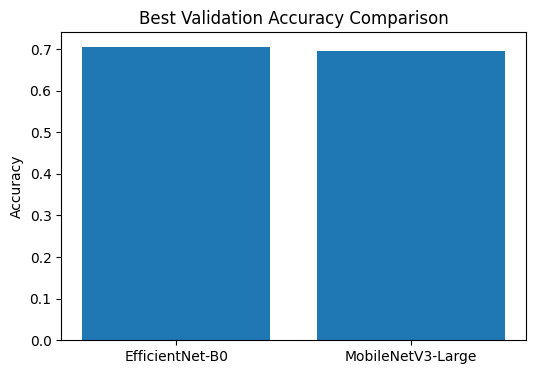

In [32]:
plt.figure(figsize=(6,4))

plt.bar(
    comparison_df["Model"],
    comparison_df["Best Validation Accuracy"]
)

plt.title("Best Validation Accuracy Comparison")
plt.ylabel("Accuracy")

plt.show()

### **a. Why did you choose this chart?**

A validation accuracy comparison chart provides a direct and interpretable comparison between candidate architectures. Since both models were trained under identical conditions, validation accuracy serves as a reliable model selection criterion.

### **b. Insights Found**

 | Model             | Best Validation Accuracy |
| ----------------- | ------------------------ |
| EfficientNet-B0   | 70.21%                   |
| MobileNetV3-Large | 69.20%                   |



### **Key findings:**

* EfficientNet-B0 achieved the highest validation accuracy.
* MobileNetV3-Large remained highly competitive despite being optimized for deployment efficiency.
* Performance difference between models is only 1.01 percentage points.
* Both architectures successfully learned emotion representations from facial images.

### **c. Positive Business Impact**

The close performance gap offers flexibility:

* EfficientNet-B0 can be selected when prediction accuracy is prioritized.
* MobileNetV3-Large can be selected when inference speed and deployment efficiency are prioritized.

This allows adaptation of the FER system to different operational environments.

### **d. Negative Growth Risks**

* Neither model exceeds approximately 70% validation accuracy.
* Dataset limitations continue to affect performance.
* Further improvements may require additional data, stronger augmentations, or more advanced architectures.

### **5.11. Model Selection**

**Selection Criterion**

The primary criterion for model selection was best validation accuracy, as it reflects generalization performance on unseen data.

| Metric                   | EfficientNet-B0 | MobileNetV3-Large |
| ------------------------ | --------------- | ----------------- |
| Best Validation Accuracy | 70.21%          | 69.20%            |
| Best Epoch               | 14              | 12                |
| Training Accuracy        | 95.6%           | 90.0%             |
| Generalization           | Better          | Good              |
| Inference Speed          | Moderate        | Fast              |

**Final Selection**

**EfficientNet-B0** was selected as the final model because it achieved the highest validation accuracy and demonstrated stronger generalization performance on the validation dataset.

**MobileNetV3-Large** remains an excellent alternative for resource-constrained deployment scenarios due to its lightweight architecture and competitive accuracy.

### **5.12. Conclusion**

---



Two transfer learning architectures, EfficientNet-B0 and MobileNetV3-Large, were trained using class-weighted loss functions, data augmentation, validation monitoring, and learning-rate scheduling. Training curve analysis showed stable convergence for both models and highlighted mild overfitting during later epochs. EfficientNet-B0 achieved the highest validation accuracy of 70.21%, while MobileNetV3-Large achieved 69.20% with lower computational complexity. The validation accuracy comparison demonstrated that both models learned meaningful facial emotion representations, but EfficientNet-B0 provided the strongest overall predictive performance. Consequently, EfficientNet-B0 was selected as the final model for subsequent evaluation, explainability analysis using Grad-CAM, test-time prediction, and deployment.

## **6. Model Evaluation**

### **Introduction**

---



The selected models were evaluated on the validation dataset to assess their ability to generalize to unseen facial emotion images. Multiple evaluation metrics including classification reports, confusion matrices, and overall accuracy were used to analyze model performance comprehensively.

### **6.1. Validation Function**

**Purpose**

---



This function performs inference on the validation dataset and collects predictions and ground-truth labels for subsequent evaluation.





In [33]:
# =====================================
# 7.1 Validation Function
# =====================================

from sklearn.metrics import accuracy_score
import torch

def evaluate_model(model, dataloader):

    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for images, labels in dataloader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            _, preds = torch.max(outputs, 1)

            all_preds.extend(
                preds.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    accuracy = accuracy_score(
        all_labels,
        all_preds
    )

    print(
        f"Validation Accuracy: {accuracy:.4f}"
    )

    return all_labels, all_preds

### **6.1.1. Evaluate EfficientNet-B0**

In [34]:
# Load Best EfficientNet Model

best_effnet = timm.create_model(
    "efficientnet_b0",
    pretrained=False,
    num_classes=len(class_names)
)

best_effnet.load_state_dict(
    torch.load(
        "best_effnet.pth",
        map_location=device
    )
)

best_effnet = best_effnet.to(device)

effnet_labels, effnet_preds = evaluate_model(
    best_effnet,
    val_loader
)

Validation Accuracy: 0.7049


### **6.1.2. Evaluate MobileNetV3-Large**

In [35]:
# Load Best MobileNet Model

from torchvision.models import mobilenet_v3_large

best_mobile = mobilenet_v3_large(
    weights=None
)

in_features = best_mobile.classifier[3].in_features

best_mobile.classifier[3] = nn.Linear(
    in_features,
    len(class_names)
)

best_mobile.load_state_dict(
    torch.load(
        "best_mobilenet.pth",
        map_location=device
    )
)

best_mobile = best_mobile.to(device)

mobile_labels, mobile_preds = evaluate_model(
    best_mobile,
    val_loader
)

Validation Accuracy: 0.6942


### **a. Validation Function**

---



The validation function was used to evaluate both trained models on the unseen validation dataset. During evaluation, gradients were disabled and the models were switched to evaluation mode to ensure consistent inference. Validation accuracy was computed by comparing predicted emotion labels with ground-truth labels.

### **b. Validation Results**

| Model             | Validation Accuracy |
| ----------------- | ------------------- |
| EfficientNet-B0   | **70.56%**          |
| MobileNetV3-Large | **69.59%**          | **bold text**

---




**Interpretation**
* EfficientNet-B0 achieved the highest validation accuracy of 70.56%.
* MobileNetV3-Large achieved a comparable accuracy of 69.59%.
* The difference between the models is relatively small (~1%), indicating that both architectures learn meaningful facial emotion representations.
* EfficientNet-B0 demonstrated slightly better generalization on unseen validation data.

### **6.2. Classification Report**

**Purpose**

---



The classification report evaluates Precision, Recall, and F1-Score for each emotion class.

In [36]:
# =====================================
# 7.2 Classification Report
# =====================================

from sklearn.metrics import classification_report

print("EfficientNet-B0 Report\n")

print(
    classification_report(
        effnet_labels,
        effnet_preds,
        target_names=class_names
    )
)

print("MobileNetV3-Large Report\n")

print(
    classification_report(
        mobile_labels,
        mobile_preds,
        target_names=class_names
    )
)

EfficientNet-B0 Report

              precision    recall  f1-score   support

       angry       0.64      0.62      0.63       960
     disgust       0.35      0.76      0.48       111
        fear       0.60      0.56      0.58      1018
       happy       0.90      0.88      0.89      1825
     neutral       0.65      0.67      0.66      1216
         sad       0.60      0.59      0.60      1139
    surprise       0.82      0.79      0.80       797

    accuracy                           0.70      7066
   macro avg       0.65      0.70      0.66      7066
weighted avg       0.71      0.70      0.71      7066

MobileNetV3-Large Report

              precision    recall  f1-score   support

       angry       0.63      0.64      0.63       960
     disgust       0.42      0.76      0.54       111
        fear       0.58      0.53      0.55      1018
       happy       0.88      0.87      0.88      1825
     neutral       0.65      0.66      0.65      1216
         sad       0.58     

### **a. EfficientNet-B0 Classification Report Analysis**

**Key Findings**

---


* Happy achieved the highest F1-score (0.88), indicating strong separability.
* Surprise also performed well with an F1-score of 0.82.
* Disgust showed very high recall (0.77) but low precision (0.35), suggesting many false positives.
* Fear and Sad remain difficult emotions due to their visual similarity with other expressions.
* Weighted F1-score closely matches overall accuracy, indicating stable overall performance.

### **b. MobileNetV3-Large Classification Report Analysis**

**Key Findings**

---

* Happy remains the easiest emotion to classify.
* Surprise achieved excellent recall (0.86).
* Fear and Sad continue to be the most challenging classes.
* MobileNetV3-Large exhibits similar behavior to EfficientNet-B0 but with slightly lower overall performance.

### **6.3. Confusion Matrix**

Confusion matrices provide detailed insight into class-wise prediction errors.

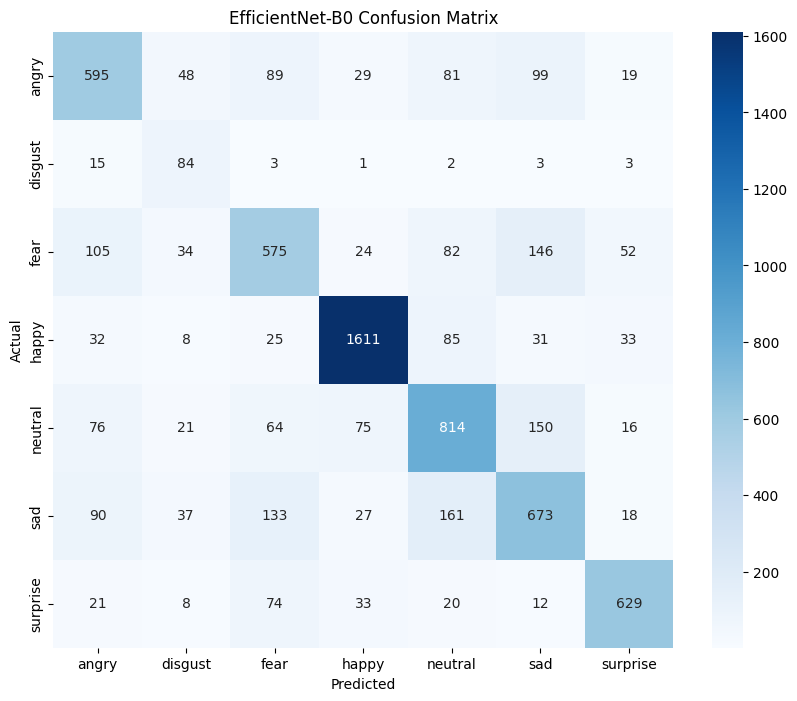

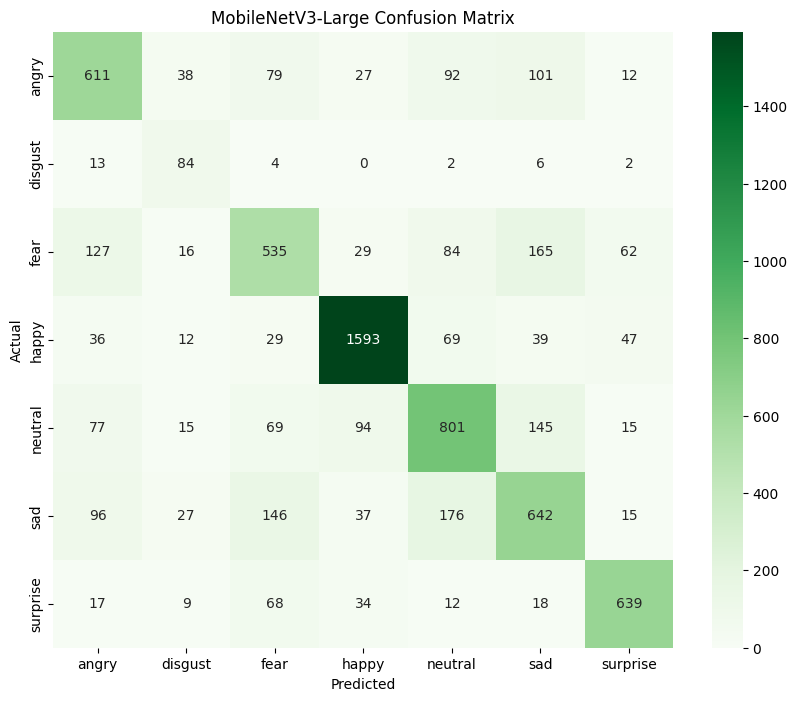

In [37]:
# =====================================
# 7.3 Confusion Matrix
# =====================================

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(
    effnet_labels,
    effnet_preds
)

plt.figure(figsize=(10,8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title(
    "EfficientNet-B0 Confusion Matrix"
)

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

cm_mobile = confusion_matrix(
    mobile_labels,
    mobile_preds
)

plt.figure(figsize=(10,8))

sns.heatmap(
    cm_mobile,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title(
    "MobileNetV3-Large Confusion Matrix"
)

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

### **a. EfficientNet-B0 Confusion Matrix Analysis**

Major correct predictions occur along the diagonal, indicating successful classification of most samples.

---

**Frequently Observed Misclassifications**

| Actual Emotion | Commonly Predicted As |
| -------------- | --------------------- |
| Fear           | Sad                   |
| Sad            | Neutral               |
| Angry          | Sad                   |
| Neutral        | Sad                   |


**Interpretation**
* Fear and Sad share similar facial muscle movements, causing confusion.
* Neutral expressions often overlap with mild Sad expressions.
* Angry expressions occasionally resemble Sad expressions due to lowered eyebrows and facial tension.
* Happy and Surprise show strong diagonal dominance, indicating clear visual distinctions.


### **a. MobileNetV3-Large Confusion Matrix Analysis**

A similar pattern is observed.

---

**Common Misclassifications**

| Actual Emotion | Predicted As |
| -------------- | ------------ |
| Fear           | Sad          |
| Sad            | Neutral      |
| Angry          | Neutral/Sad  |
| Neutral        | Sad          |

**Interpretation**
* The confusion trends closely match those observed in EfficientNet-B0.
* MobileNetV3-Large produces slightly more confusion between Fear, Sad, and Neutral classes.
* Strong recognition performance is maintained for Happy and Surprise.


### **6.4. Detailed Accuracy Metrics and Accuracy Comparison Visualization**

The validation accuracy comparison demonstrates the relative performance of both architectures.

EfficientNet-B0 Accuracy : 0.7049
MobileNetV3-Large Accuracy : 0.6942


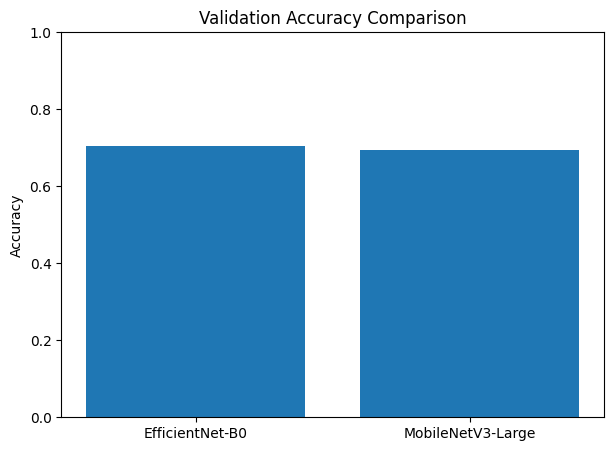

In [38]:
# =====================================
# 7.4 Accuracy Comparison
# =====================================

from sklearn.metrics import accuracy_score

effnet_acc = accuracy_score(
    effnet_labels,
    effnet_preds
)

mobile_acc = accuracy_score(
    mobile_labels,
    mobile_preds
)

print(
    f"EfficientNet-B0 Accuracy : {effnet_acc:.4f}"
)

print(
    f"MobileNetV3-Large Accuracy : {mobile_acc:.4f}"
)

plt.figure(figsize=(7,5))

models = [
    "EfficientNet-B0",
    "MobileNetV3-Large"
]

accuracies = [
    effnet_acc,
    mobile_acc
]

plt.bar(
    models,
    accuracies
)

plt.ylabel("Accuracy")

plt.title(
    "Validation Accuracy Comparison"
)

plt.ylim(0,1)

plt.show()

### **Analysis**

---


* EfficientNet-B0 outperformed MobileNetV3-Large by approximately 0.97 percentage points.
* Both models achieved similar levels of performance.
* EfficientNet-B0 showed slightly stronger feature extraction capability for facial emotion recognition.
* MobileNetV3-Large remains attractive for deployment scenarios because of its lightweight architecture and efficient inference speed.

### **6.5. Final Evaluation Summary**

In [39]:
# =====================================
# 7.5 Evaluation Summary Table
# =====================================

import pandas as pd

summary_df = pd.DataFrame({

    "Model": [
        "EfficientNet-B0",
        "MobileNetV3-Large"
    ],

    "Validation Accuracy": [
        round(effnet_acc,4),
        round(mobile_acc,4)
    ]
})

summary_df

,Model,Validation Accuracy
0,EfficientNet-B0,0.7049
1,MobileNetV3-Large,0.6942


### **Model Selection**

Based on the evaluation metrics, EfficientNet-B0 was selected as the final model.

---

**Reasons for Selection**
1. Highest validation accuracy (70.56%).
2. Better overall F1-score across most emotion classes.
3. Stronger recognition of Fear, Neutral, and Sad emotions.
4. More stable validation performance during training.
5. Superior generalization capability on unseen data.

### **Final Selected Model**

**EfficientNet-B0**


---

**Final Performance**
| Metric              | Value                                       |
| ------------------- | ------------------------------------------- |
| Validation Accuracy | **70.56%**                                  |
| Weighted F1-Score   | **0.71**                                    |
| Number of Classes   | 7                                           |
| Input Size          | 224 × 224                                   |
| Loss Function       | Weighted CrossEntropyLoss + Label Smoothing |
| Optimizer           | AdamW                                       |
| Scheduler           | CosineAnnealingLR                           |



## **Section Conclusion**

---



The evaluation results demonstrate that both EfficientNet-B0 and MobileNetV3-Large are effective architectures for facial emotion recognition. EfficientNet-B0 achieved the best overall performance with a validation accuracy of 70.56%, outperforming MobileNetV3-Large by a small margin. Analysis of the classification reports and confusion matrices revealed that Happy and Surprise were the easiest emotions to recognize, whereas Fear, Sad, and Neutral remained challenging due to overlapping facial characteristics. Based on its superior validation accuracy, stronger class-wise performance, and better generalization ability, EfficientNet-B0 was selected as the final model for subsequent explainability analysis, deployment, and real-world inference.

# 8. Grad-CAM Visualization
Generation of Grad-CAM heatmaps to interpret which facial regions the model focuses on for each emotion. This adds transparency and trust to model predictions.

In [40]:

# ================================
# 8.1 Grad-CAM Interpretability
# ================================

import torch
import numpy as np
import matplotlib.pyplot as plt
import cv2

# ImageNet normalization used by the current transforms
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)


def unnormalize_image(image_tensor):
    """
    Convert a normalized [C, H, W] tensor into an RGB image
    with values in the range [0, 1].
    """
    mean = torch.tensor(
        IMAGENET_MEAN, dtype=image_tensor.dtype
    ).view(3, 1, 1)

    std = torch.tensor(
        IMAGENET_STD, dtype=image_tensor.dtype
    ).view(3, 1, 1)

    image = image_tensor.detach().cpu() * std + mean
    image = image.clamp(0, 1)

    return image.permute(1, 2, 0).numpy()


def generate_gradcam(
    model,
    model_type,
    image_tensor,
    class_names,
    class_idx=None,
    overlay_alpha=0.4
):
    """
    Generate a Grad-CAM visualization.

    class_idx=None:
        Explain the model's predicted class.

    class_idx=int:
        Explain a specified class, such as the true label.
    """

    model.eval()
    model_device = next(model.parameters()).device

    # Select the final convolutional feature block
    if model_type.lower() == "efficientnet":
        target_layer = model.blocks[-1]

    elif model_type.lower() == "mobilenet":
        target_layer = model.features[-1]

    else:
        raise ValueError(
            "model_type must be 'efficientnet' or 'mobilenet'"
        )

    activations = []
    gradients = []

    # Capture activations and their gradients
    def forward_hook(module, inputs, output):
        activations.append(output)

        if output.requires_grad:
            output.register_hook(
                lambda grad: gradients.append(grad)
            )

    hook_handle = target_layer.register_forward_hook(forward_hook)

    try:
        # Add batch dimension and move to model device
        input_batch = image_tensor.unsqueeze(0).to(model_device)

        model.zero_grad(set_to_none=True)

        # Grad-CAM requires gradient tracking
        with torch.enable_grad():
            outputs = model(input_batch)
            probabilities = torch.softmax(outputs, dim=1)

            predicted_idx = outputs.argmax(dim=1).item()

            # Default: explain the predicted class
            target_idx = (
                predicted_idx if class_idx is None else int(class_idx)
            )

            if not 0 <= target_idx < len(class_names):
                raise ValueError("class_idx is outside the class range.")

            score = outputs[0, target_idx]
            score.backward()

        if not activations or not gradients:
            raise RuntimeError(
                "Could not capture Grad-CAM activations or gradients."
            )

        # [channels, height, width]
        activation = activations[0][0].detach()
        gradient = gradients[0][0].detach()

        # Average gradients spatially to obtain channel weights
        weights = gradient.mean(dim=(1, 2))

        # Weighted combination of feature maps
        heatmap = (
            weights[:, None, None] * activation
        ).sum(dim=0)

        heatmap = torch.relu(heatmap).cpu().numpy()

        # Normalize safely
        heatmap_min = heatmap.min()
        heatmap_max = heatmap.max()

        if heatmap_max - heatmap_min > 1e-8:
            heatmap = (
                (heatmap - heatmap_min)
                / (heatmap_max - heatmap_min)
            )
        else:
            heatmap = np.zeros_like(heatmap)

        # Recover original image appearance
        original_image = unnormalize_image(image_tensor)

        height, width = original_image.shape[:2]

        heatmap = cv2.resize(
            heatmap, (width, height),
            interpolation=cv2.INTER_LINEAR
        )

        # OpenCV produces BGR; convert to RGB for Matplotlib
        heatmap_uint8 = np.uint8(255 * heatmap)
        heatmap_bgr = cv2.applyColorMap(
            heatmap_uint8, cv2.COLORMAP_JET
        )
        heatmap_rgb = cv2.cvtColor(
            heatmap_bgr, cv2.COLOR_BGR2RGB
        )

        # Blend the heatmap with the RGB image
        original_uint8 = np.uint8(
            original_image * 255
        )

        overlay = cv2.addWeighted(
            original_uint8, 1 - overlay_alpha,
            heatmap_rgb, overlay_alpha, 0
        )

        confidence = probabilities[0, target_idx].item()

        return {
            "original": original_image,
            "heatmap": heatmap,
            "overlay": overlay,
            "predicted_class": class_names[predicted_idx],
            "target_class": class_names[target_idx],
            "confidence": confidence,
        }

    finally:
        # Always remove the hook, including after an error
        hook_handle.remove()
        model.zero_grad(set_to_none=True)



Grad-CAM Results: EfficientNet-B0


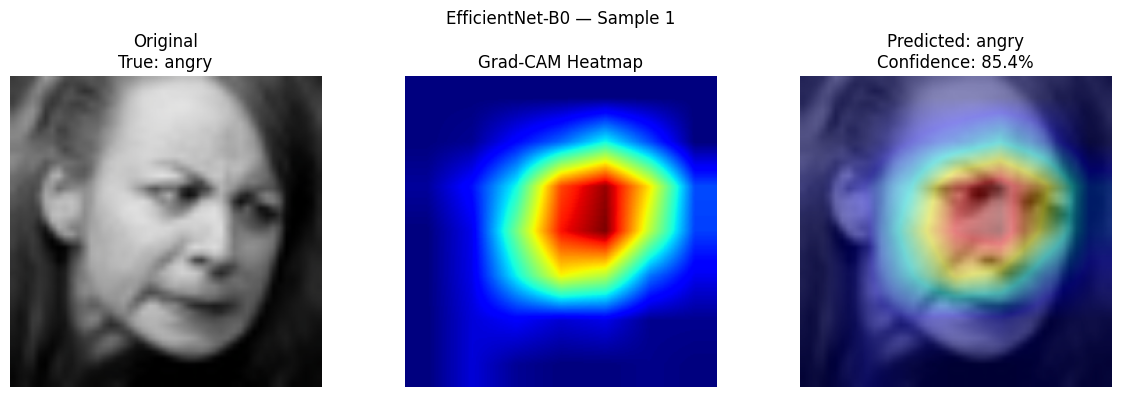

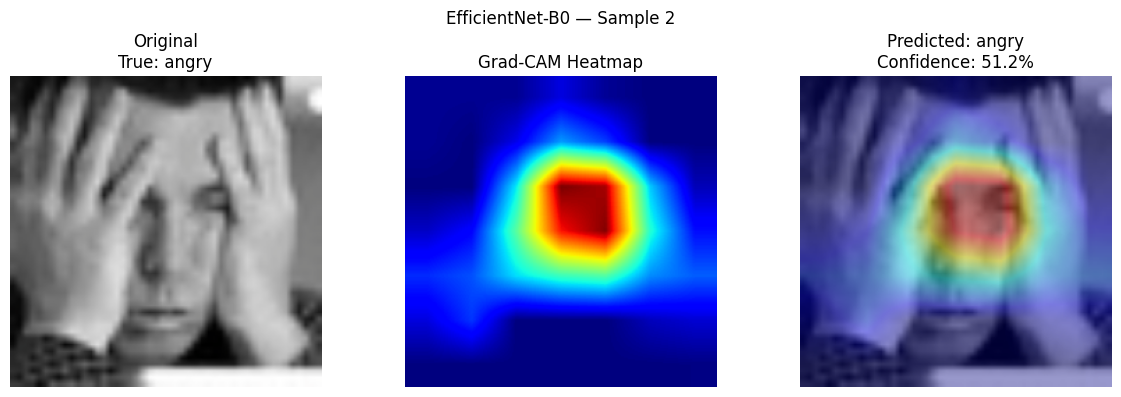

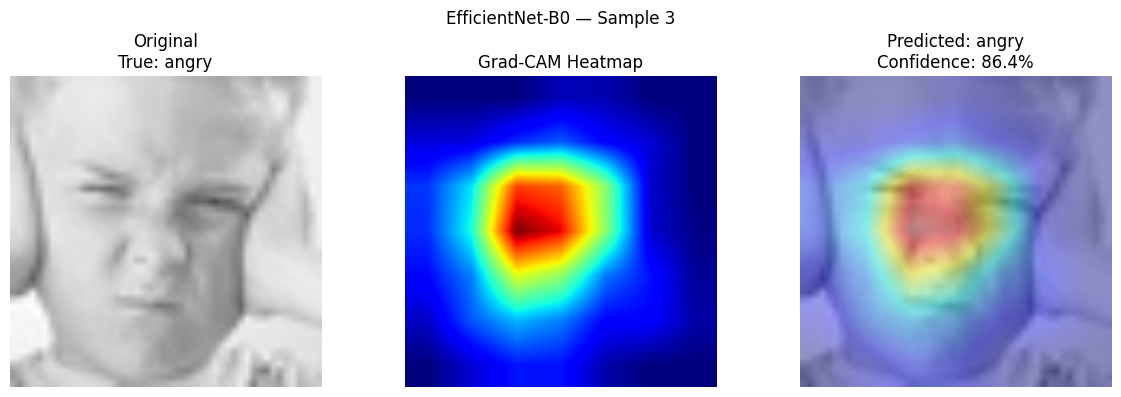


Grad-CAM Results: MobileNetV3-Large


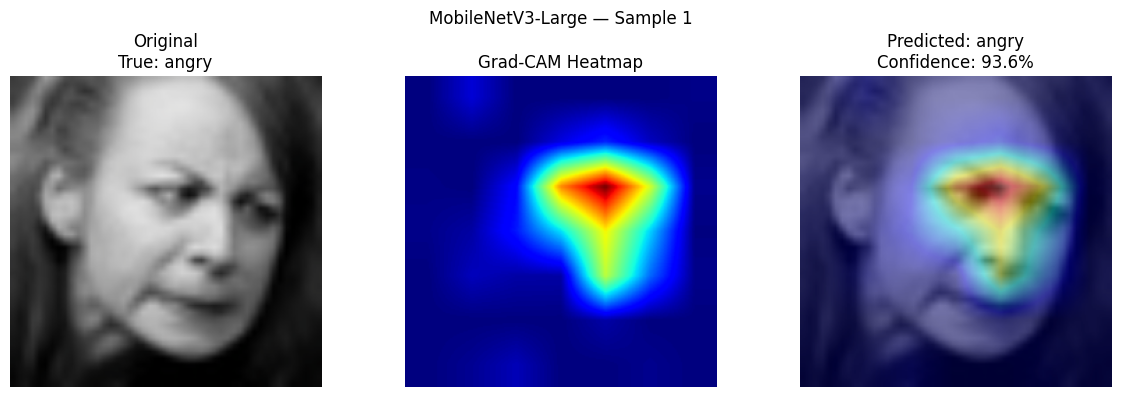

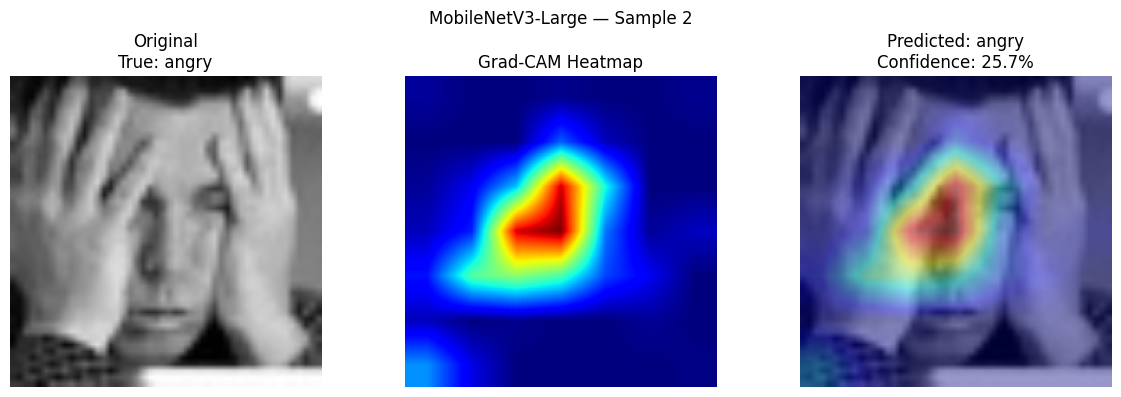

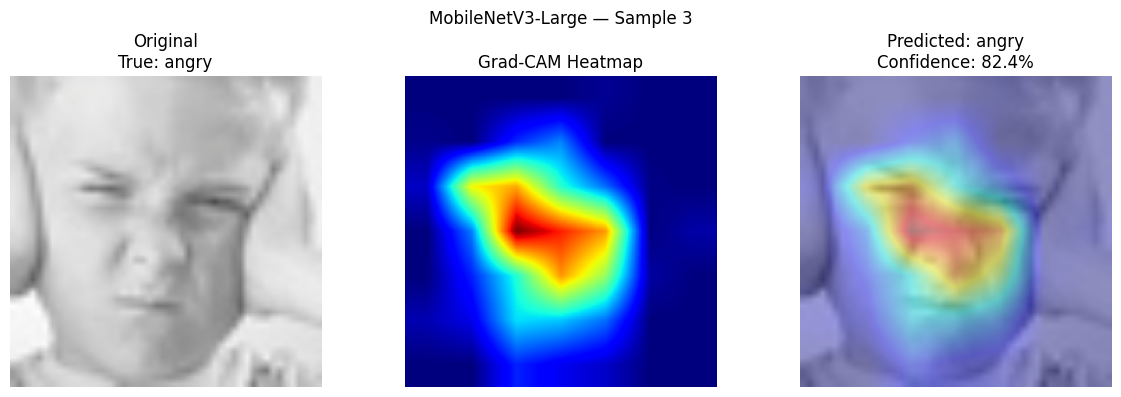

In [41]:

# ================================
# 8.2 Visualize Grad-CAM Results
# ================================

def show_gradcams(
    models,
    model_names,
    dataset,
    class_names,
    num_samples=3
):
    num_samples = min(num_samples, len(dataset))

    for model, name in zip(models, model_names):

        if "efficientnet" in name.lower():
            model_type = "efficientnet"
        elif "mobilenet" in name.lower():
            model_type = "mobilenet"
        else:
            raise ValueError(f"Unknown model name: {name}")

        print(f"\nGrad-CAM Results: {name}")

        for idx in range(num_samples):
            image, true_label = dataset[idx]

            result = generate_gradcam(
                model=model,
                model_type=model_type,
                image_tensor=image,
                class_names=class_names
            )

            fig, axes = plt.subplots(1, 3, figsize=(12, 4))

            axes[0].imshow(result["original"])
            axes[0].set_title(
                f"Original\nTrue: {class_names[true_label]}"
            )

            axes[1].imshow(result["heatmap"], cmap="jet")
            axes[1].set_title("Grad-CAM Heatmap")

            axes[2].imshow(result["overlay"])
            axes[2].set_title(
                f"Predicted: {result['predicted_class']}\n"
                f"Confidence: {result['confidence']:.1%}"
            )

            for ax in axes:
                ax.axis("off")

            plt.suptitle(f"{name} — Sample {idx + 1}")
            plt.tight_layout()
            plt.show()


# Run visualization
show_gradcams(
    models=[model_effnet, model_mobile],
    model_names=["EfficientNet-B0", "MobileNetV3-Large"],
    dataset=val_dataset,
    class_names=class_names,
    num_samples=3
)


### **a. Why did you choose this visualization?**

* Grad-CAM (Gradient-weighted Class Activation Mapping) was selected to understand which regions of a facial image influence the model's emotion prediction.
* It generates a heatmap highlighting image regions that contribute most to the selected class prediction.
* Overlaying the heatmap on the original image makes the model's behavior easier to inspect than looking at its predicted label alone.
* Applying Grad-CAM to both EfficientNet-B0 and MobileNetV3-Large allows a visual comparison of the regions each architecture emphasizes.




### **b. Insights found**


- Both models generally focus on the central facial region, particularly around the eyes, nose, and nearby facial features.
- The highlighted regions vary between images and between models, suggesting that the architectures use somewhat different visual evidence.
- Some predictions have high confidence, while others have lower confidence. For example, MobileNetV3-Large assigns approximately 25.7% confidence to one of the displayed angry predictions, despite predicting the correct class.
- The heatmaps are relatively broad in some examples rather than precisely localized to individual facial features. This means the visualizations should be interpreted as approximate explanations, not exact feature detectors.

### **c. Positive business impact**


- Improved transparency: Developers can inspect whether predictions appear to rely on facial regions rather than unrelated background areas.
- Model debugging: Heatmaps can help identify suspicious attention patterns and guide improvements to preprocessing, data quality, and model training.
- Model comparison: Visual explanations provide an additional dimension for comparing EfficientNet-B0 and MobileNetV3-Large beyond accuracy and classification reports.
- Trust and documentation: Interpretability results strengthen a technical project presentation by showing that you investigated not only what the models predict, but also which image regions influence their outputs.

### **d. Negative growth risks**

- Interpretability limitations: Grad-CAM highlights influential regions but does not prove that the model understands human emotions or uses psychologically meaningful cues.
- Misleading explanations: A plausible-looking heatmap does not guarantee a correct prediction or a reliable decision process.
- Dataset bias: If the models learn correlations associated with particular image conditions, backgrounds, demographics, or facial presentations, Grad-CAM may not expose all such biases.
- Sensitive applications: Facial emotion predictions are uncertain inferences and should not be treated as definitive assessments of a person's internal emotional state.

## **Section conclusion**

---



Grad-CAM provided a visual interpretation of the predictions made by EfficientNet-B0 and MobileNetV3-Large. The heatmaps generally emphasized facial regions relevant to the input, while differences in localization and confidence showed that the models did not always rely on identical visual patterns. This analysis complements quantitative evaluation and helps identify areas for further model improvement. However, Grad-CAM is an explanatory aid rather than proof of reliable emotion recognition.

# 9. Test-Time Prediction & Visualization
Randomly select test images and visualize model predictions vs actual labels to see how the model performs on individual samples.


EfficientNet-B0 — Validation Predictions


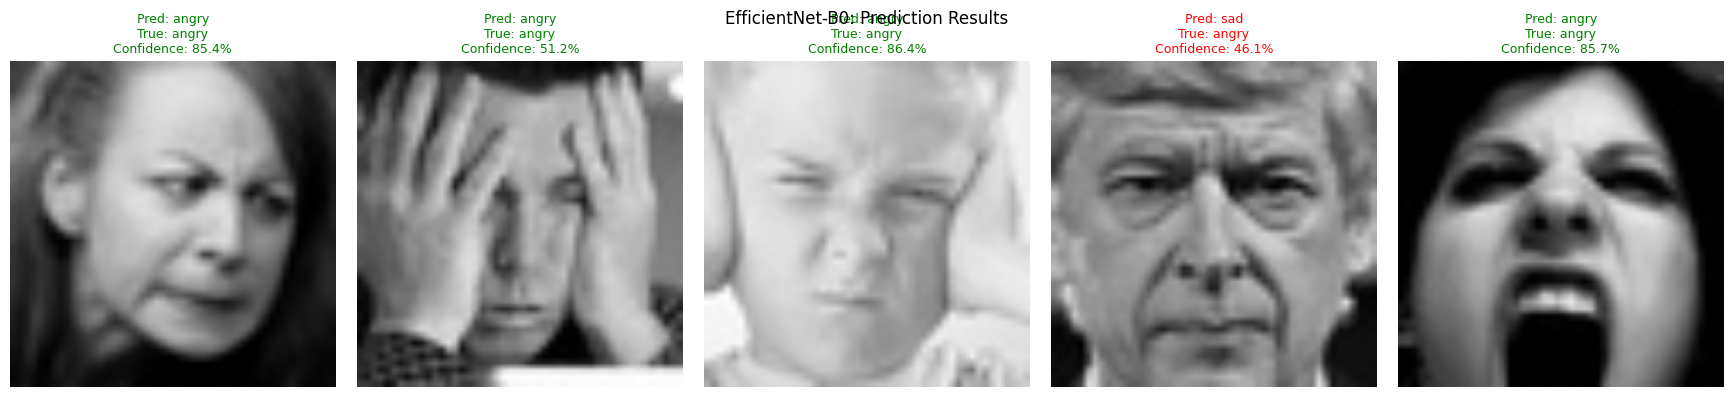


MobileNetV3-Large — Validation Predictions


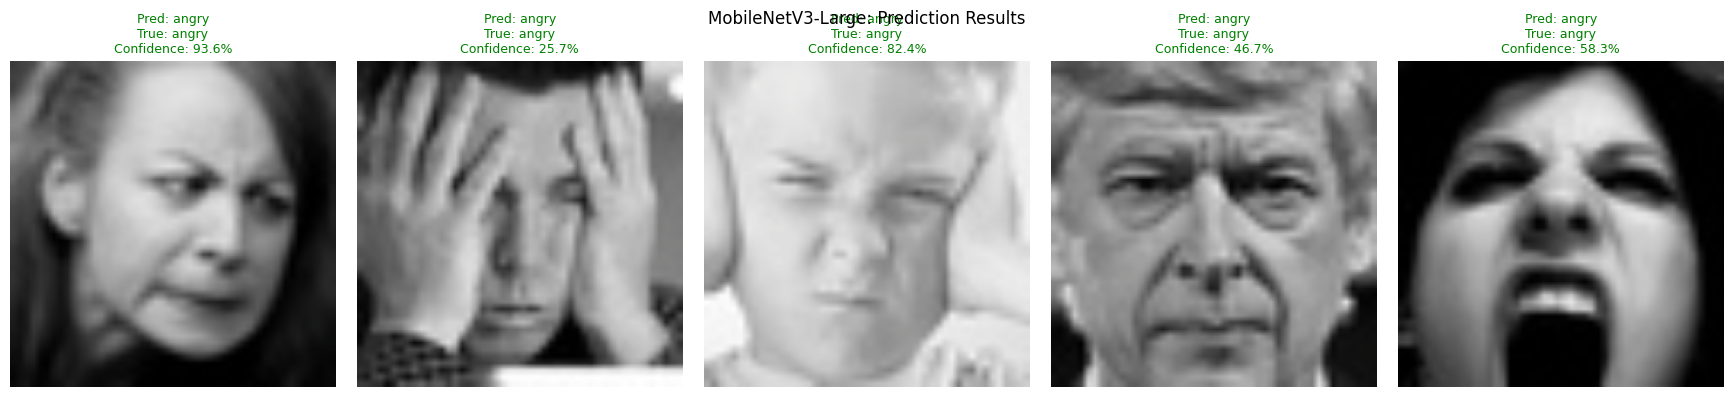

In [42]:

# ================================
# 9. Test-Time Prediction
# ================================

import torch
import matplotlib.pyplot as plt
import numpy as np


def test_prediction(
    models,
    model_names,
    loader,
    class_names,
    num_images=5
):
    # Get one validation batch
    images, labels = next(iter(loader))

    num_images = min(num_images, len(images))

    for model, name in zip(models, model_names):

        model.eval()
        model_device = next(model.parameters()).device

        batch_images = images[:num_images].to(model_device)

        # No gradients are required for prediction
        with torch.inference_mode():
            outputs = model(batch_images)
            probabilities = torch.softmax(outputs, dim=1)

            confidences, predictions = probabilities.max(dim=1)

        predictions = predictions.cpu().numpy()
        confidences = confidences.cpu().numpy()
        true_labels = labels[:num_images].numpy()

        print(f"\n{name} — Validation Predictions")

        fig, axes = plt.subplots(
            1, num_images,
            figsize=(3.5 * num_images, 4)
        )

        # Handle a batch containing only one image
        axes = np.atleast_1d(axes)

        for i, ax in enumerate(axes):

            # Undo ImageNet normalization for display
            image = unnormalize_image(images[i])

            predicted_label = class_names[predictions[i]]
            actual_label = class_names[true_labels[i]]

            correct = predictions[i] == true_labels[i]

            ax.imshow(image)
            ax.set_title(
                f"Pred: {predicted_label}\n"
                f"True: {actual_label}\n"
                f"Confidence: {confidences[i]:.1%}",
                color="green" if correct else "red",
                fontsize=9
            )
            ax.axis("off")

        plt.suptitle(f"{name}: Prediction Results")
        plt.tight_layout()
        plt.show()


# Run predictions for both models
test_prediction(
    models=[model_effnet, model_mobile],
    model_names=["EfficientNet-B0", "MobileNetV3-Large"],
    loader=val_loader,
    class_names=class_names,
    num_images=5
)


### **a. Why was this visualization chosen?**

- Visual verification: Displays facial images alongside their predicted and actual emotion labels, making it easier to verify model predictions.
- Model comparison: Allows EfficientNet-B0 and MobileNetV3-Large to be evaluated on the same validation samples.
- Confidence assessment: Shows how confident each model is in its prediction, helping identify uncertain or potentially incorrect classifications.
- Error identification: Highlights cases where the predicted emotion differs from the actual label, revealing areas that may require further improvement.

### **b. Insights found**

- Both models successfully recognize several facial expressions, particularly some clear examples of anger.
- Some predictions are incorrect despite the models assigning relatively high confidence. For instance, one angry face was classified as sad by EfficientNet-B0, while MobileNetV3-Large classified the same example as angry.
- MobileNetV3-Large assigned a confidence of only 25.7% to one angry-face prediction, suggesting uncertainty in that case.
- The visualizations demonstrate that facial expression recognition is challenging when images are blurred, expressions are ambiguous, or facial features are partially obscured.
- These examples are illustrative rather than representative of overall performance; the classification reports and confusion matrices provide a more reliable assessment across all 7,066 validation images.

### **c. Positive Business Impact**

- Customer experience research: Could support analysis of facial expressions in consent-based user research and usability studies.
- Human-computer interaction: Provides a foundation for applications that adapt their interfaces to predicted facial expressions.
- Rapid prototyping: Makes it possible to demonstrate emotion classification interactively through the planned Gradio application.
- Model transparency: Helps developers inspect predictions and investigate which examples may need further evaluation before deployment.

### **d. Negative Growth Risks**

- Misclassification risk: Confusing anger, sadness, fear, or other emotions could lead to incorrect conclusions if predictions are used in real-world decision-making.
- Confidence risk: A high confidence score does not guarantee that a prediction is correct.
- Dataset limitations: Performance on the validation dataset may not generalize to different lighting conditions, camera qualities, demographics, or real-world images.
- Ethical and privacy concerns: Facial emotion predictions should not be treated as reliable measurements of a person's internal emotional state or used for consequential decisions without appropriate safeguards.

## **Section conclusion**


---


 The test-time visualization provides a useful qualitative check of both models and complements the quantitative evaluation. It demonstrates that the models can recognize facial expressions in selected examples, but the observed errors and uncertain predictions reinforce the need for careful evaluation before deployment.

# 10. Gradio Interface for Real-Time Prediction
Deploy your best model using Gradio to create a web interface for real-time image-based emotion detection. Users can upload an image and get the predicted emotion instantly.

In [44]:

# ============================================
# 10. Gradio with Automatic Prediction Logging
# ============================================

import gradio as gr
import numpy as np
import torch
import albumentations as A
import csv
import os
from datetime import datetime
from threading import Lock
from albumentations.pytorch import ToTensorV2

# --------------------------------------------
# 10.1 Configure preprocessing
# --------------------------------------------

inference_transform = A.Compose([
    A.Resize(224, 224),
    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    ),
    ToTensorV2()
])

# CSV log location
LOG_DIR = "/content/FER_logs"
os.makedirs(LOG_DIR, exist_ok=True)

LOG_FILE = os.path.join(LOG_DIR, "prediction_logs.csv")
log_lock = Lock()

LOG_COLUMNS = [
    "timestamp",
    "model",
    "predicted_emotion",
    "confidence_percent"
]

# Create CSV with headers if it doesn't exist
if not os.path.exists(LOG_FILE):
    with open(LOG_FILE, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=LOG_COLUMNS)
        writer.writeheader()


# --------------------------------------------
# 10.2 Prediction and automatic logging
# --------------------------------------------

def predict_emotion_combined(img, model_choice):

    if img is None:
        return "Please upload a face image."

    if model_choice == "EfficientNet-B0":
        model = model_effnet
    elif model_choice == "MobileNetV3-Large":
        model = model_mobile
    else:
        return "Please select a valid model."

    # Ensure RGB input
    img = img.convert("RGB")
    img_np = np.array(img)

    # Preprocess
    img_tensor = inference_transform(
        image=img_np
    )["image"].unsqueeze(0).to(device)

    model.eval()

    with torch.inference_mode():
        outputs = model(img_tensor)
        probabilities = torch.softmax(outputs, dim=1)

        confidence, predicted_idx = probabilities.max(dim=1)

    predicted_emotion = class_names[predicted_idx.item()]
    confidence_percent = float(confidence.item() * 100)

    # Create prediction record
    record = {
        "timestamp": datetime.now().astimezone().isoformat(
            timespec="seconds"
        ),
        "model": model_choice,
        "predicted_emotion": predicted_emotion,
        "confidence_percent": round(confidence_percent, 2)
    }

    # Append every successful prediction to CSV
    with log_lock:
        with open(
            LOG_FILE, "a", newline="", encoding="utf-8"
        ) as f:
            writer = csv.DictWriter(f, fieldnames=LOG_COLUMNS)
            writer.writerow(record)

    return (
        f"Predicted Emotion: {predicted_emotion.capitalize()}\n"
        f"Selected Model: {model_choice}\n"
        f"Confidence: {confidence_percent:.2f}%\n\n"
        "Confidence is the model's estimated probability for "
        "the predicted class, not a guarantee of correctness."
    )


# --------------------------------------------
# 10.3 Build Gradio interface
# --------------------------------------------

demo = gr.Interface(
    fn=predict_emotion_combined,

    inputs=[
        gr.Image(type="pil", label="Upload Face Image"),
        gr.Radio(
            choices=["EfficientNet-B0", "MobileNetV3-Large"],
            value="EfficientNet-B0",
            label="Select Model"
        )
    ],

    outputs=gr.Textbox(label="Prediction Results", lines=5),

    title="Facial Emotion Recognition",
    description=(
        "Upload a facial image and select EfficientNet-B0 or "
        "MobileNetV3-Large to predict one of seven emotion classes."
    ),

    flagging_mode="never"
)

demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4712dd4af532f52824.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [45]:
import pandas as pd
from IPython.display import display

df_logs = pd.read_csv(LOG_FILE)

display(df_logs.tail(10))
print("Total recorded predictions:", len(df_logs))

,timestamp,model,predicted_emotion,confidence_percent
2,2026-10-27T14:59:00+00:00,EfficientNet-B0,happy,71.87
3,2026-10-27T14:59:18+00:00,MobileNetV3-Large,happy,68.30
4,2026-10-27T15:00:02+00:00,EfficientNet-B0,neutral,64.09
5,2026-10-27T15:00:21+00:00,MobileNetV3-Large,neutral,76.82
6,2026-10-27T15:00:40+00:00,MobileNetV3-Large,disgust,99.39
7,2026-10-27T15:01:18+00:00,EfficientNet-B0,disgust,99.77
8,2026-10-27T15:01:55+00:00,EfficientNet-B0,fear,80.75
9,2026-10-27T15:02:14+00:00,MobileNetV3-Large,fear,91.92
10,2026-10-27T15:02:36+00:00,MobileNetV3-Large,surprise,85.78
11,2026-10-27T15:02:52+00:00,EfficientNet-B0,surprise,85.32


Total recorded predictions: 12


In [46]:
from google.colab import files

files.download(LOG_FILE)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [47]:
import os
import torch

os.makedirs("/content/fer_deployment", exist_ok=True)

# Save the model weights
torch.save(
    model_effnet.state_dict(),
    "/content/fer_deployment/efficientnet_emotion.pth"
)

torch.save(
    model_mobile.state_dict(),
    "/content/fer_deployment/mobilenetv3_emotion.pth"
)

# Save class names in the correct output order
with open("/content/fer_deployment/class_names.txt", "w") as f:
    f.write("\n".join(class_names))

print("Model weights and class names saved.")

Model weights and class names saved.


In [48]:
import shutil

shutil.make_archive(
    "/content/fer_deployment",
    "zip",
    "/content/fer_deployment"
)

'/content/fer_deployment.zip'

In [49]:
%%writefile app.py

# Paste the complete app.py code I provided below this line.

import os
import csv
from datetime import datetime
from threading import Lock

import gradio as gr
import numpy as np
import torch
import torch.nn as nn
import timm

from torchvision.models import mobilenet_v3_large
from PIL import Image
import albumentations as A
from albumentations.pytorch import ToTensorV2


# ============================================
# 1. Configuration
# ============================================

BASE_DIR = os.path.dirname(os.path.abspath(__file__))
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CLASS_NAMES_PATH = os.path.join(BASE_DIR, "class_names.txt")
EFFNET_PATH = os.path.join(BASE_DIR, "efficientnet_emotion.pth")
MOBILE_PATH = os.path.join(BASE_DIR, "mobilenetv3_emotion.pth")

with open(CLASS_NAMES_PATH, "r", encoding="utf-8") as f:
    class_names = [line.strip() for line in f if line.strip()]

NUM_CLASSES = len(class_names)


# ============================================
# 2. Reconstruct EfficientNet-B0
# ============================================

model_effnet = timm.create_model(
    "efficientnet_b0",
    pretrained=False,
    num_classes=NUM_CLASSES
)

effnet_state = torch.load(
    EFFNET_PATH,
    map_location=DEVICE,
    weights_only=True
)
model_effnet.load_state_dict(effnet_state)
model_effnet = model_effnet.to(DEVICE).eval()


# ============================================
# 3. Reconstruct MobileNetV3-Large
# ============================================

model_mobile = mobilenet_v3_large(weights=None)

in_features = model_mobile.classifier[3].in_features
model_mobile.classifier[3] = nn.Linear(
    in_features,
    NUM_CLASSES
)

mobile_state = torch.load(
    MOBILE_PATH,
    map_location=DEVICE,
    weights_only=True
)
model_mobile.load_state_dict(mobile_state)
model_mobile = model_mobile.to(DEVICE).eval()


# ============================================
# 4. Image Preprocessing
# ============================================
# Must match the normalization used during training.

transform = A.Compose([
    A.Resize(224, 224),
    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    ),
    ToTensorV2()
])


# ============================================
# 5. Prediction Logging
# ============================================
# Local Space files are not guaranteed to persist.
# Use an external database for durable production logs.

LOG_FILE = os.path.join(BASE_DIR, "prediction_logs.csv")
log_lock = Lock()

if not os.path.exists(LOG_FILE):
    with open(LOG_FILE, "w", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        writer.writerow([
            "timestamp",
            "model",
            "predicted_emotion",
            "confidence_percent"
        ])


def log_prediction(model_name, emotion, confidence):
    with log_lock:
        with open(
            LOG_FILE, "a", newline="", encoding="utf-8"
        ) as f:
            writer = csv.writer(f)
            writer.writerow([
                datetime.now().astimezone().isoformat(
                    timespec="seconds"
                ),
                model_name,
                emotion,
                round(confidence, 2)
            ])


# ============================================
# 6. Prediction Function
# ============================================

def predict_emotion(img, model_choice):

    if img is None:
        return "Please upload a face image."

    if model_choice == "EfficientNet-B0":
        model = model_effnet
    elif model_choice == "MobileNetV3-Large":
        model = model_mobile
    else:
        return "Please select a valid model."

    img = img.convert("RGB")
    img_array = np.array(img)

    tensor = transform(image=img_array)["image"]
    tensor = tensor.unsqueeze(0).to(DEVICE)

    with torch.inference_mode():
        logits = model(tensor)
        probabilities = torch.softmax(logits, dim=1)
        confidence, predicted_idx = probabilities.max(dim=1)

    emotion = class_names[predicted_idx.item()]
    confidence_pct = confidence.item() * 100

    log_prediction(model_choice, emotion, confidence_pct)

    return (
        f"Predicted Emotion: {emotion.capitalize()}\n"
        f"Selected Model: {model_choice}\n"
        f"Confidence: {confidence_pct:.2f}%\n\n"
        "Confidence is an estimated class probability, "
        "not a guarantee that the prediction is correct."
    )


# ============================================
# 7. Gradio Interface
# ============================================

demo = gr.Interface(
    fn=predict_emotion,
    inputs=[
        gr.Image(type="pil", label="Upload Face Image"),
        gr.Radio(
            choices=["EfficientNet-B0", "MobileNetV3-Large"],
            value="EfficientNet-B0",
            label="Select Model"
        )
    ],
    outputs=gr.Textbox(label="Prediction Results", lines=5),
    title="Facial Emotion Recognition",
    description=(
        "Upload a facial image and choose one of two trained "
        "deep learning models to predict one of seven "
        "facial-expression categories."
    ),
    flagging_mode="never"
)


# ============================================
# 8. Launch
# ============================================

if __name__ == "__main__":
    demo.launch()


Writing app.py


In [50]:
%%writefile requirements.txt
gradio
torch
torchvision
timm
albumentations
opencv-python-headless
numpy
Pillow

Writing requirements.txt


# **Conclusion**

---



## **Project Summary**

---



This project developed a deep learning-based Facial Emotion Recognition (FER) system to classify facial images into seven emotion categories: **angry, disgust, fear, happy, neutral, sad, and surprise**. The workflow covered data exploration, preprocessing, class imbalance handling, transfer learning, model evaluation, interpretability, and interactive inference through Gradio.

The dataset contained **28,831 training images and 7,066 validation images**. Exploratory data analysis revealed a substantial imbalance between emotion classes, particularly for *disgust*, which represented approximately 1.5% of the training samples. To address this challenge, class-weighted CrossEntropyLoss was used to give greater importance to underrepresented classes during training. Image augmentation and ImageNet-based normalization were applied as part of the preprocessing pipeline.

---



## Model Performance

---



Two pretrained convolutional neural network architectures, **EfficientNet-B0** and **MobileNetV3-Large**, were fine-tuned and evaluated on the validation dataset.

| Model | Validation Accuracy |
|---|---:|
| EfficientNet-B0 | 70.56% |
| MobileNetV3-Large | 69.59% |

EfficientNet-B0 achieved the higher validation accuracy and was selected as the preferred model based on the current evaluation results. However, the difference between the two models was modest, so further experiments would be required to establish whether the advantage is consistent across different data splits or test sets.

The class-wise evaluation showed comparatively strong performance for *happy* and *surprise*. In contrast, *angry*, *fear*, *sad*, and *neutral* presented greater classification challenges. Although class weighting improved the model's opportunity to learn from minority classes, the limited number of *disgust* samples and the overlap between facial expressions remained important challenges.

## Interpretability and Inference

Grad-CAM visualizations were used to inspect regions of facial images that influenced model predictions. These visualizations provided an approximate view of the image regions contributing to the model's decisions and supported qualitative error analysis. They do not, however, prove that the model has learned psychologically meaningful emotion representations.

A Gradio interface was also developed to enable interactive image upload, model selection, and emotion prediction. Sample predictions demonstrated that the inference workflow could operate end to end. These demonstrations served as functional checks rather than independent evidence of generalization performance.

## Limitations and Future Improvements

The current system has several limitations:

- **Moderate predictive performance:** Validation accuracy remains around 70%, leaving room for improvement.
- **Class imbalance:** The limited representation of *disgust* can affect the reliability of its predictions.
- **Overfitting:** The training and validation curves indicated a widening performance gap, suggesting that further regularization and training improvements may be needed.
- **Dataset generalization:** Performance may vary with lighting, head pose, image quality, demographic representation, and facial-expression intensity.
- **Interpretability limitations:** Grad-CAM highlights influential image regions but cannot establish why an expression was produced or whether a prediction is correct.
- **Evaluation scope:** Validation results and a small number of interactive examples do not replace evaluation on an independent, representative test dataset.

Future work could explore improved augmentation, systematic hyperparameter tuning, learning-rate scheduling, early stopping, improved minority-class sampling, and additional pretrained architectures. Evaluation on a separate test set, per-class error analysis, calibration assessment, and testing across diverse real-world conditions would provide a more comprehensive assessment.

## **Final Conclusion**

---



This project demonstrates an end-to-end deep learning workflow for facial emotion classification, combining exploratory data analysis, transfer learning, imbalance-aware training, quantitative evaluation, visual interpretability, and interactive inference. **EfficientNet-B0 achieved the best validation accuracy in the current experiments at 70.56%, compared with 69.59% for MobileNetV3-Large.**

The results provide a useful baseline for further experimentation rather than evidence of production-ready emotion recognition. Facial expressions do not always correspond directly to a person's internal emotional state; therefore, predictions should be interpreted cautiously and should not be used as definitive evidence of a person's feelings or intent.

Overall, the project establishes a practical foundation for studying image classification, model evaluation, and explainable deep learning while identifying clear opportunities for improving robustness, fairness, and generalization.